# 02. Análisis exploratorio y estadística descriptiva

**Notebook anterior:** *01_limpieza_integracion_movielens.ipynb*

### Objetivo
Documentar propiedades a partir de tablas consolidadas.



## Preparación del entorno y lectura reproducible
El notebook busca el directorio `data/processed` generado en la etapa anterior, en su ausencia, permite ejecutarse con los dataset colocados junto al notebook o dentro de una carpeta indicada. No requiere los archivos originales.

Muestra cantidad de registros y cantidad de variables en los dataset trabajados.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

FILES = [
    "column_quality.csv", "genre_frequency.csv", "key_checks.csv",
    "movie_genres.csv", "movies_consolidated.csv", "movies_without_ratings.csv",
    "movies_without_tags.csv", "post_validation.csv", "quality_overview.csv",
    "rating_aggregates_by_movie.csv", "rating_distribution.csv",
    "referential_integrity.csv", "tag_aggregates_by_movie.csv",
    "title_duplicates_exact.csv"
]


DATA_DIR_OVERRIDE = None
cwd = Path.cwd().resolve()
candidates = ([Path(DATA_DIR_OVERRIDE).expanduser().resolve()] if DATA_DIR_OVERRIDE else []) + [
    p / "data" / "processed" for p in (cwd, *cwd.parents)
] + [cwd, cwd / "data" / "processed", cwd / "archivos", Path("/mnt/data")]
DATA_DIR = next((p for p in candidates if p.is_dir() and all((p / f).is_file() for f in FILES)), None)
if DATA_DIR is None:
    raise FileNotFoundError("No se localizaron los dataset. Configura DATA_DIR_OVERRIDE con la carpeta donde se encuentran.")

tables = {Path(f).stem: pd.read_csv(DATA_DIR / f, low_memory=False) for f in FILES}
movies = tables["movies_consolidated"]
movie_genres = tables["movie_genres"]
rating_dist = tables["rating_distribution"].copy()
print("Directorio de datos:", DATA_DIR)
#print("Bases cargadas:", len(tables))
display(pd.DataFrame([{"archivo": f"{k}.csv", "registros": len(v), "variables": v.shape[1]} for k,v in tables.items()]))
assert len(tables) == 14
assert movies["movieId"].is_unique, "movies_consolidated debe tener una película por fila"
assert not movie_genres.duplicated(["movieId", "genre"]).any(), "Duplicación película-género"

Directorio de datos: C:\Users\jorge\Desktop\DMEMCD_2026\Proyecto_Integrador_M1\data\processed


,archivo,registros,variables
0,column_quality.csv,14,7
1,genre_frequency.csv,20,3
2,key_checks.csv,4,5
3,movie_genres.csv,154170,2
4,movies_consolidated.csv,87585,20
5,movies_without_ratings.csv,3153,3
6,movies_without_tags.csv,36262,3
7,post_validation.csv,6,2
8,quality_overview.csv,4,8
9,rating_aggregates_by_movie.csv,84432,7


### Sesgos y límites de inferencia (mapear al final como conclusión)
- **Autoselección:** quienes califican películas no constituyen una muestra aleatoria de todas las personas ni de todos los espectadores.
- **Popularidad y supervivencia de actividad:** las películas con mayor exposición acumulan más observaciones; medias de títulos con pocos votos son menos estables.
- **Sesgo de cobertura:** los títulos sin evaluaciones participan en el catálogo, pero no en la distribución de notas observadas.
- **Granularidad y ponderación:** una media de medias por película pondera todos los títulos igual; la media global de evaluaciones pondera por número de eventos.
- **Géneros multilabel:** una película puede pertenecer a varios géneros; sumar las frecuencias de géneros no produce el total de películas.
- **No causalidad:** una correlación entre actividad y puntuación no demuestra que una variable genere la otra.

## Clasificación de variables, escalas de medición y comparaciones permitidas

### ¿Qué variables están disponibles para el análisis?

Para garantizar que a lo largo del análisis, se implementen las interpretaciones de las variables de manera homologada, se construye un diccionario estadístico documentado para cada uno de las variables que tenemos disponibles - y con las cuales estaremos trabajando.

Para cada variable se registran los siguiente atributos:
- **Tipo estadístico:** naturaleza de la variable -> Cuantitativa o Cualitativa.
- **Escala de medición:** nominal, ordinal, intervalo o razón.
- **Unidad o significado:** descripción conceptual de la información almacenada.
- **Comparaciones permitidas:** operaciones estadísticas e interpretaciones válidas de acuerdo con su escala de medición.
- **Tipo en Python:** tipo de dato utilizado en el DataFrame de Pandas.

El diccionario se genera automáticamente a partir de una estructura de metadatos previamente definida, permitiendo documentar tanto variables originales como variables resultantes de la transformación y limpieza.

De manera complementaria, se incorpora una validación mediante una instrucción `assert` que verifica que todas las columnas presentes en el DataFrame estén clasificadas dentro del diccionario de metadatos. En caso de detectarse una nueva variable sin documentación, el proceso se interrumpe y solicita su clasificación antes de continuar con el análisis.

In [2]:
# 3. DICCIONARIO ESTADÍSTICO DOCUMENTADO
metadata = {
"movieId": ("Cualitativa nominal", "Nominal", "ID de película", "Igualdad, unión, conteos de películas"),
"title_clean": ("Cualitativa nominal", "Nominal", "Título limpio", "Frecuencias y títulos duplicados"),
"title": ("Cualitativa nominal", "Nominal", "Título", "Frecuencias y títulos duplicados"),
"genres": ("Cualitativa nominal multilabel", "Nominal", "Lista de géneros", "Pertenencia y proporciones por categoría"),
"genres_original": ("Cualitativa nominal multilabel", "Nominal", "Géneros originales", "Comparación de categorías"),
"year": ("Cuantitativa discreta derivada", "Razón", "Año de estreno", "Tendencias temporales y agrupación por periodos"),
"genre": ("Cualitativa nominal", "Nominal", "Género individual", "Frecuencias y cobertura por género"),
"imdbId": ("Cualitativa nominal", "Nominal", "ID IMDb", "Unicidad y enlaces"),
"tmdbId": ("Cualitativa nominal", "Nominal", "ID TMDb", "Unicidad y enlaces"),
"rating": ("Cualitativa ordinal (valores discretos)", "Ordinal; intervalo aproximado para medias", "Puntos (0.5–5)", "Orden, frecuencias, cuartiles; media bajo supuesto"),
"rating_count": ("Cuantitativa discreta", "Razón", "Número de evaluaciones", "Diferencias, cocientes, cuantiles, dispersión"),
"rating_users": ("Cuantitativa discreta", "Razón", "Usuarios que evaluaron", "Diferencias, cocientes, dispersión"),
"rating_mean": ("Cuantitativa continua derivada", "Intervalo aproximado", "Puntos por película", "Diferencias; media/correlación con cautela"),
"rating_std": ("Cuantitativa continua derivada", "Razón (magnitud de dispersión)", "Puntos por película", "Comparación de dispersión; no aplica con n<2"),
"rating_min": ("Cuantitativa derivada discreta", "Ordinal", "Puntos", "Orden y comparación de extremos"),
"rating_max": ("Cuantitativa derivada discreta", "Ordinal", "Puntos", "Orden y comparación de extremos"),
"tag_application_count": ("Cuantitativa discreta", "Razón", "Etiquetas por película", "Frecuencias, cocientes y dispersión"),
"non_null_tag_count": ("Cuantitativa discreta", "Razón", "Etiquetas con texto", "Frecuencias, cocientes y dispersión"),
"distinct_tags": ("Cuantitativa discreta", "Razón", "Etiquetas únicas por película", "Conteos y comparación de diversidad textual"),
"tag_users": ("Cuantitativa discreta", "Razón", "Usuarios con etiquetas", "Conteos y comparaciones"),
"has_ratings": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Proporciones y tablas cruzadas"),
"has_tags": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Proporciones y tablas cruzadas"),
"has_imdb_id": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Cobertura de identificadores"),
"has_tmdb_id": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Cobertura de identificadores"),
}
dictionary = pd.DataFrame([{
    "variable": c, "tipo_estadístico": metadata.get(c, ("Revisar", "Revisar", "", ""))[0],
    "escala": metadata.get(c, ("Revisar", "Revisar", "", ""))[1],
    "unidad/significado": metadata.get(c, ("", "", "Revisar", ""))[2],
    "comparaciones_permitidas": metadata.get(c, ("", "", "", "Revisar"))[3],
    "tipo_python": str(movies[c].dtype)
} for c in movies.columns])
display(dictionary)
assert not dictionary["tipo_estadístico"].eq("Revisar").any(), "Clasifica cualquier columna nueva antes de analizarla"

,variable,tipo_estadístico,escala,unidad/significado,comparaciones_permitidas,tipo_python
0,movieId,Cualitativa nominal,Nominal,ID de película,"Igualdad, unión, conteos de películas",int64
1,title_clean,Cualitativa nominal,Nominal,Título limpio,Frecuencias y títulos duplicados,object
2,year,Cuantitativa discreta derivada,Razón,Año de estreno,Tendencias temporales y agrupación por periodos,float64
3,genres,Cualitativa nominal multilabel,Nominal,Lista de géneros,Pertenencia y proporciones por categoría,object
4,imdbId,Cualitativa nominal,Nominal,ID IMDb,Unicidad y enlaces,int64
5,tmdbId,Cualitativa nominal,Nominal,ID TMDb,Unicidad y enlaces,float64
6,rating_count,Cuantitativa discreta,Razón,Número de evaluaciones,"Diferencias, cocientes, cuantiles, dispersión",int64
7,rating_mean,Cuantitativa continua derivada,Intervalo aproximado,Puntos por película,Diferencias; media/correlación con cautela,float64
8,rating_std,Cuantitativa continua derivada,Razón (magnitud de dispersión),Puntos por película,Comparación de dispersión; no aplica con n<2,float64
9,rating_min,Cuantitativa derivada discreta,Ordinal,Puntos,Orden y comparación de extremos,float64


## 1. Frecuencias Categóricas y Ordinales

#### ¿Cómo se distribuyen las calificaciones?

El objetivo será identificar qué puntuaciones son más frecuentes y determinar si las valoraciones de los usuarios tienden a concentrarse en niveles bajos, medios o altos.

Para responder esta pregunta analizamos la tabla `ratings`, donde cada fila es una calificación emitida por un usuario a una película. Como la calificación es una **variable categórica ordinal** (toma valores ordenados de 0.5 a 5 en pasos de 0.5), la representamos con un **gráfico de barras** que muestra la frecuencia de cada valor. Así vemos cuáles son los más comunes y qué tan concentradas o dispersas están las evaluaciones.

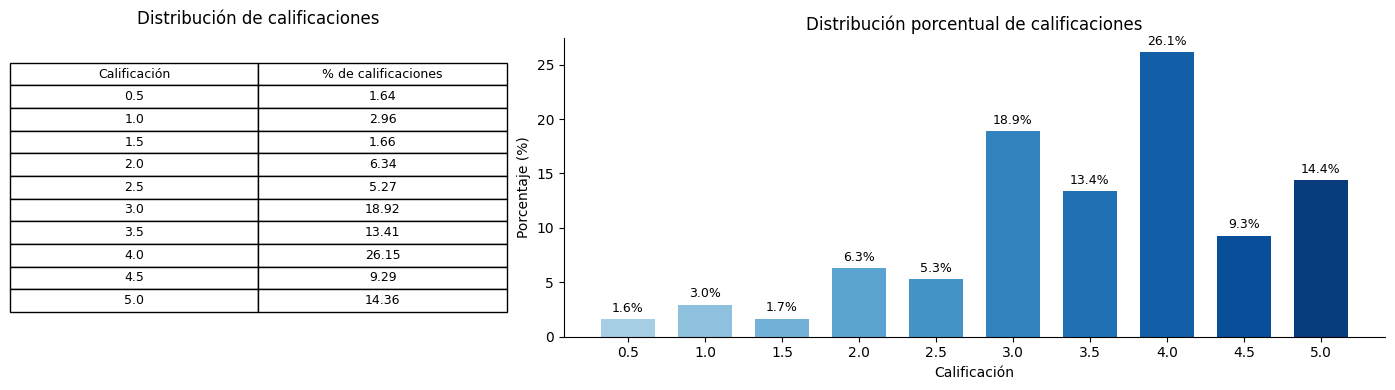

La calificación 4.0 es la más frecuente del conjunto de datos.


In [45]:
# Utilizaremos la tabla ratings_dist la cual contiene los datos para responder esta pregunta
rd = rating_dist

fig, (ax_tabla, ax_grafica) = plt.subplots(
    1, 2,
    figsize=(14, 4),
    gridspec_kw={"width_ratios": [1.1, 2]}
)

# ------------------
# Tabla
# ------------------
ax_tabla.axis("off")

tabla = (
    rd[["rating", "percentage"]]
    .rename(columns={
        "rating": "Calificación",
        "percentage": "% de calificaciones"
    })
)

tabla["% de calificaciones"] = tabla["% de calificaciones"].round(2)

tbl = ax_tabla.table(
    cellText=tabla.values,
    colLabels=tabla.columns,
    cellLoc="center",
    loc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.1, 1.4)

ax_tabla.set_title("Distribución de calificaciones", pad=10)

# ------------------
# Gráfica
# ------------------
colores = plt.cm.Blues(np.linspace(0.35, 0.95, len(rd)))

barras = ax_grafica.bar(
    rd["rating"].astype(str),
    rd["percentage"],
    color=colores,
    width=0.7
)

ax_grafica.bar_label(
    barras,
    labels=[f"{p:.1f}%" for p in rd["percentage"]],
    padding=3,
    fontsize=9
)

ax_grafica.set_xlabel("Calificación")
ax_grafica.set_ylabel("Porcentaje (%)")
ax_grafica.set_title("Distribución porcentual de calificaciones")
ax_grafica.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

# Calificación más frecuente
top_rating = rd.loc[rd["percentage"].idxmax()]
rating = top_rating["rating"]

print(f"La calificación {rating} es la más frecuente del conjunto de datos.")

**Interpretación.** La distribución de las calificaciones está desplazada hacia la parte alta de la escala. El valor más frecuente es **4.0 (26.1% de las calificaciones)**, seguido de **3.0 (18.9%)** y **5.0 (14.4%)**. Las calificaciones de 3.5 o más representan cerca de **[63]%** del total, mientras que las menores a 3 suman solo cerca de **[18]%**. También se observa que los valores enteros se usan más que los intermedios: por ejemplo, 4.0 es considerablemente más frecuente que 3.5 o 4.5.

Como los usuarios tienden a calificar alto, un promedio de 3.0, aunque esté por encima del punto medio de la escala, puede considerarse bajo en comparación con lo habitual.

**Limitaciones.** Cada barra cuenta calificaciones, no usuarios, por lo que quienes califican más películas pesan más. 

#### ¿Cuál es la distribución de los géneros dentro del catálogo de películas y cuáles son los géneros más y menos representados?

Analizar la frecuencia de los géneros permite conocer la composición del catálogo e identificar qué tipos de películas tienen mayor y menor representación. Esta información ayuda a comprender la diversidad de contenidos disponibles y proporciona contexto para análisis posteriores sobre preferencias de los usuarios o sistemas de recomendación.

Las películas pueden pertenecer a múltiples géneros, por lo que una misma obra puede contabilizarse en más de una categoría. En consecuencia, los porcentajes representan la proporción de películas asociadas a cada género respecto al catálogo total y no deben interpretarse como categorías mutuamente excluyentes.

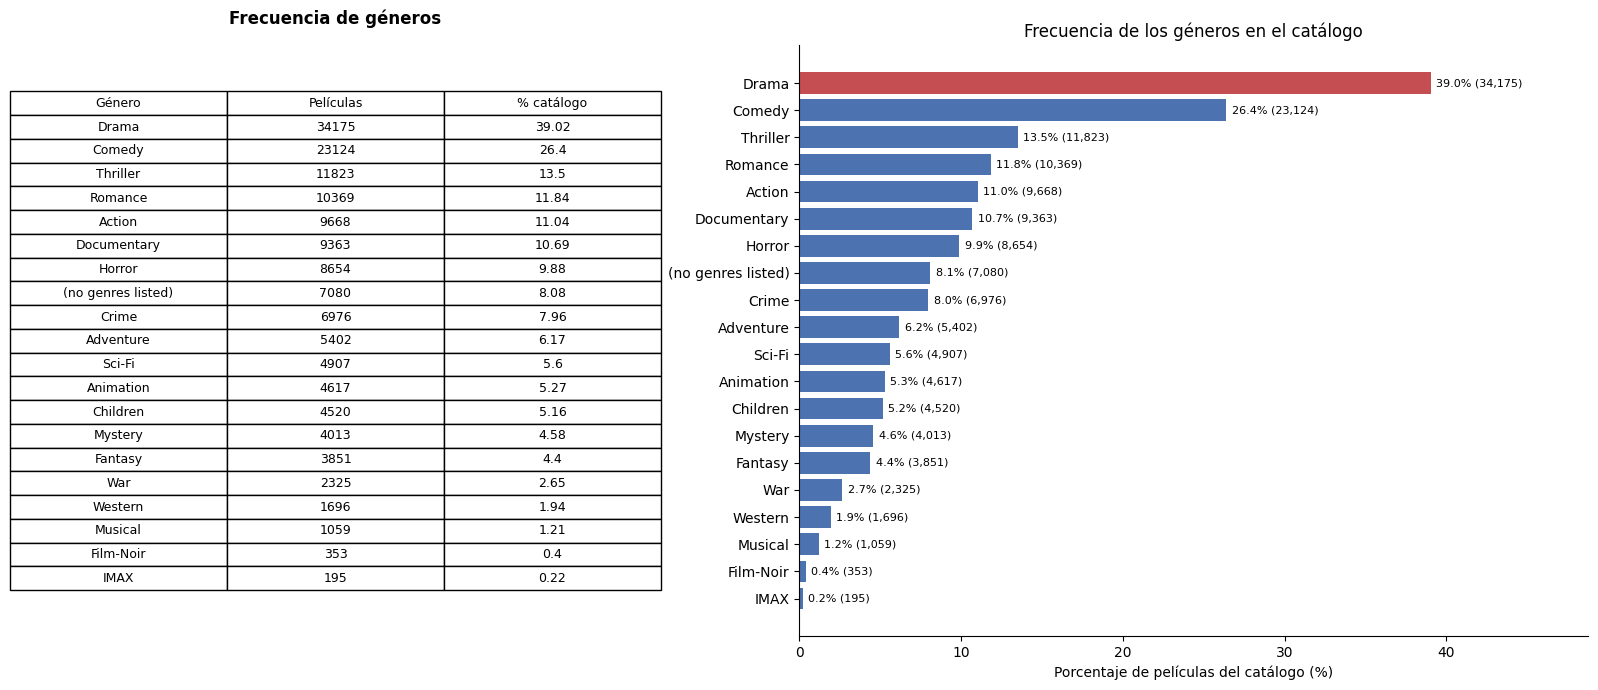

In [46]:
# Tabla de frecuencias
g = (
    movie_genres.groupby("genre", dropna=False)["movieId"]
    .nunique()
    .sort_values(ascending=False)
    .rename("peliculas")
    .reset_index()
)

g["porcentaje_catalogo"] = (
    100 * g["peliculas"] / movies["movieId"].nunique()
)

# Datos para la gráfica
d = g.sort_values("peliculas")

colores = [
    "#C44E52" if genero == "Drama" else "#4C72B0"
    for genero in d["genre"]
]

# Figura con dos columnas
fig, (ax_tabla, ax_grafica) = plt.subplots(
    1, 2,
    figsize=(16, 7),
    gridspec_kw={"width_ratios": [1.1, 1.6]}
)

# ---------- TABLA ----------
ax_tabla.axis("off")

tabla = g.copy()
tabla["porcentaje_catalogo"] = tabla["porcentaje_catalogo"].round(2)

tbl = ax_tabla.table(
    cellText=tabla.values,
    colLabels=["Género", "Películas", "% catálogo"],
    loc="center",
    cellLoc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.2, 1.3)

ax_tabla.set_title(
    "Frecuencia de géneros",
    fontsize=12,
    fontweight="bold",
    pad=15
)

# ---------- GRÁFICA ----------
barras = ax_grafica.barh(
    d["genre"],
    d["porcentaje_catalogo"],
    color=colores
)

ax_grafica.bar_label(
    barras,
    labels=[
        f"{p:.1f}% ({n:,})"
        for p, n in zip(
            d["porcentaje_catalogo"],
            d["peliculas"]
        )
    ],
    padding=4,
    fontsize=8
)

ax_grafica.set_xlim(
    0,
    d["porcentaje_catalogo"].max() * 1.25
)

ax_grafica.set_xlabel(
    "Porcentaje de películas del catálogo (%)"
)
ax_grafica.set_title(
    "Frecuencia de los géneros en el catálogo"
)
ax_grafica.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretación:** El género Drama es el más representado, apareciendo en el 39.0% de las películas del catálogo, seguido por Comedy (26.4%) y Thriller (13.5%). Esto indica una clara predominancia de contenidos dramáticos y de entretenimiento generalista. Por el contrario, géneros como Film-Noir (0.4%) e IMAX (0.2%) presentan una presencia reducida, lo que refleja su carácter más especializado dentro de la colección.

**Limitaciones:** Los resultados describen únicamente la distribución de géneros en el catálogo y no reflejan la popularidad, calidad o nivel de consumo de las películas. Además, debido a la naturaleza multietiqueta de la clasificación, una misma película puede contribuir a la frecuencia de varios géneros simultáneamente.

#### ¿Las interacciones de los usuarios se concentran en unas pocas películas o están distribuidas de manera uniforme?

Caracterizar el nivel de interacción de los usuarios con las películas mediante las acciones registradas en la plataforma. Para este análisis, se considera una **interacción** cada vez que un usuario asigna una calificación o una etiqueta a una película.

Se contabilizó el número de calificaciones (`rating_count`) y etiquetas (`tag_application_count`) recibidas por cada película. Posteriormente, las películas fueron agrupadas en intervalos de interacción (0, 1, 2-5, 6-20, 21-100, 101-1000 y más de 1000) y se calculó el porcentaje de películas perteneciente a cada intervalo respecto al total del catálogo.

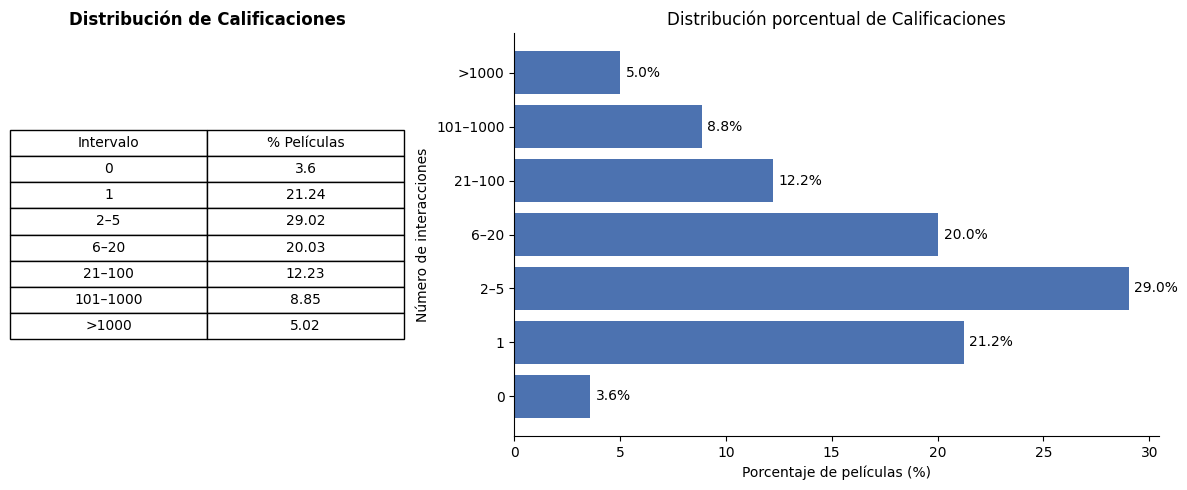

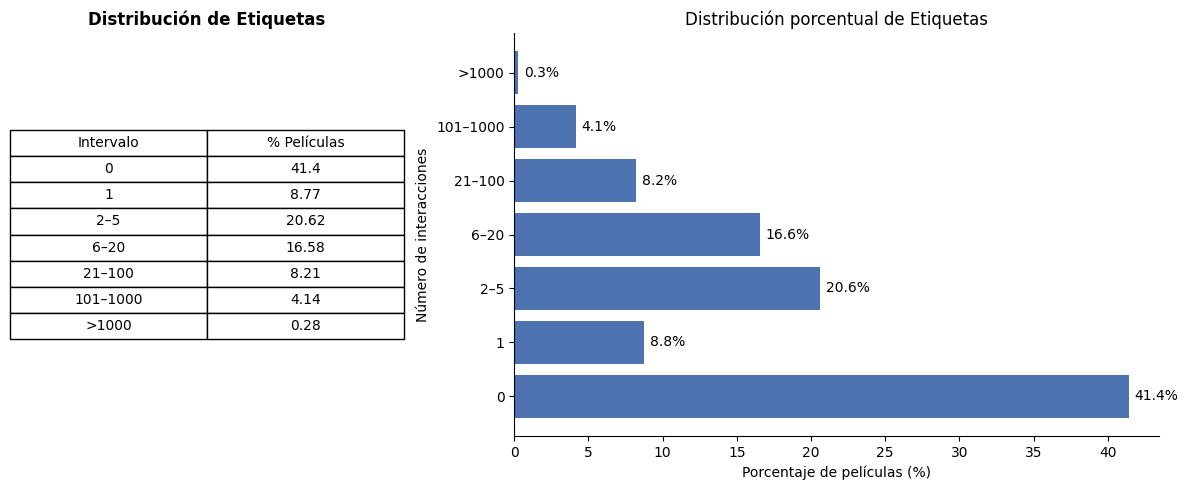

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

bins = [-0.1, 0, 1, 5, 20, 100, 1000, np.inf]
labels = ["0", "1", "2–5", "6–20", "21–100", "101–1000", ">1000"]

variables = {
    "rating_count": "Calificaciones",
    "tag_application_count": "Etiquetas"
}

for field, nombre in variables.items():

    dist = (
        pd.cut(movies[field], bins=bins, labels=labels)
        .value_counts(sort=False)
    )

    tabla = pd.DataFrame({
        "Intervalo": dist.index.astype(str),
        "% Películas": (dist.values / len(movies) * 100).round(2)
    })

    fig, (ax_table, ax_chart) = plt.subplots(
        1, 2,
        figsize=(12, 5),
        gridspec_kw={"width_ratios": [1, 1.8]}
    )

    # ---------- TABLA ----------
    ax_table.axis("off")

    tbl = ax_table.table(
        cellText=tabla.values,
        colLabels=tabla.columns,
        cellLoc="center",
        loc="center"
    )

    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1.1, 1.5)

    ax_table.set_title(
        f"Distribución de {nombre}",
        fontsize=12,
        fontweight="bold"
    )

    # ---------- GRÁFICA ----------
    barras = ax_chart.barh(
        tabla["Intervalo"],
        tabla["% Películas"],
        color="#4C72B0"
    )

    ax_chart.bar_label(
        barras,
        labels=[f"{x:.1f}%" for x in tabla["% Películas"]],
        padding=4
    )

    ax_chart.set_xlabel("Porcentaje de películas (%)")
    ax_chart.set_ylabel("Número de interacciones")
    ax_chart.set_title(
        f"Distribución porcentual de {nombre}"
    )

    ax_chart.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.show()

**Intepretación:** Los resultados muestran que la actividad de los usuarios se concentra en un conjunto reducido de películas. Más de la mitad de las películas acumula cinco o menos calificaciones, mientras que solo una pequeña proporción recibe cientos o miles de valoraciones. Este patrón también se observa en las etiquetas, aunque de forma más marcada, ya que una parte importante del catálogo no cuenta con ninguna etiqueta. En conjunto, los hallazgos sugieren que los usuarios participan con mayor frecuencia calificando películas que etiquetándolas y que la interacción se distribuye de manera desigual entre los títulos disponibles.

**Limitaciones:** 
- Las interacciones registradas reflejan únicamente la actividad observada dentro del conjunto de datos y no necesariamente la popularidad real de las películas.
- Una mayor cantidad de interacciones no implica una mejor valoración o calidad de la película.
- La agrupación por intervalos resume la distribución original y puede ocultar diferencias entre películas que pertenecen al mismo rango de interacciones.

## 4. Medidas centrales, de variabilidad y robustez

Para conteos (escala de razón) se calculan media, mediana, moda, varianza **muestral** (`ddof=1`), desviación estándar muestral, cuartiles, rango intercuartílico `Q3−Q1`, y coeficiente de variación `DE/media` cuando la media es positiva. El **CV** carece de sentido para identificadores, medias de calificaciones en escala sin cero absoluto y variables cuyo promedio sea cero. 

El IQR concentra la amplitud del 50% central de observaciones; es relativamente resistente a extremos. Como indicador de sensibilidad se compara la media original con una media recortada simétricamente al 5% y con la mediana. La media recortada **no sustituye ni elimina** registros originales.

In [48]:
# 5. DESCRIPTIVOS ROBUSTOS PARA CONTEOS A NIVEL PELÍCULA
def trimmed_mean(x, proportion=0.05):
    v = np.sort(pd.to_numeric(pd.Series(x), errors="coerce").dropna().to_numpy(dtype=float))
    k = int(len(v) * proportion)
    return float(v[k: len(v)-k].mean()) if len(v) > 2*k else np.nan

def descriptive(x, name, cv=True):
    s = pd.to_numeric(pd.Series(x), errors="coerce").dropna()
    if s.empty: return {"variable": name, "n": 0}
    q1, q3 = s.quantile([0.25, 0.75]); mu = s.mean(); sd = s.std(ddof=1)
    modes = s.mode()
    return {"variable": name, "n": int(len(s)), "media": mu, "mediana": s.median(),
            "moda": modes.iloc[0] if len(modes) else np.nan,
            "modas_totales": len(modes), "varianza_muestral": s.var(ddof=1),
            "desviacion_muestral": sd, "q1": q1, "q3": q3, "IQR": q3-q1,
            "mínimo": s.min(), "máximo": s.max(),
            "CV_pct": 100*sd/mu if cv and mu>0 else np.nan,
            "media_recortada_5pct": trimmed_mean(s),
            "cambio_media_recorte_pct": 100*(trimmed_mean(s)-mu)/mu if mu != 0 else np.nan}

count_vars = ["rating_count", "rating_users", "tag_application_count", "non_null_tag_count", "distinct_tags", "tag_users"]
count_stats = pd.DataFrame([descriptive(movies[c],c) for c in count_vars])
display(count_stats.set_index("variable").T)
print("CV: cuanto mayor es, más dispersión relativa en una misma medida de razón; no existe umbral universal.")
print("La comparación media/mediana y el cambio por recorte diagnostican sensibilidad, no prueban una distribución.")

variable,rating_count,rating_users,tag_application_count,non_null_tag_count,distinct_tags,tag_users
n,"87,585.0000","87,585.0000","87,585.0000","87,585.0000","87,585.0000","87,585.0000"
media,365.3617,365.3617,22.8358,22.8356,12.4088,3.9966
mediana,5.0000,5.0000,1.0000,1.0000,1.0000,1.0000
moda,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
modas_totales,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
varianza_muestral,"6,483,784.1555","6,483,784.1555","15,545.3252","15,545.2835","1,991.1156",400.9613
desviacion_muestral,"2,546.3276","2,546.3276",124.6809,124.6807,44.6219,20.0240
q1,2.0000,2.0000,0.0000,0.0000,0.0000,0.0000
q3,23.0000,23.0000,7.0000,7.0000,7.0000,2.0000
IQR,21.0000,21.0000,7.0000,7.0000,7.0000,2.0000


CV: cuanto mayor es, más dispersión relativa en una misma medida de razón; no existe umbral universal.
La comparación media/mediana y el cambio por recorte diagnostican sensibilidad, no prueban una distribución.


### Descriptivos de las calificaciones y distinción entre unidades
La escala de calificación es discreta y ordenada. La media y la varianza se muestran bajo la convención habitual de tratar los saltos de 0.5 como intervalos comparables. Los descriptivos **por evento** usan frecuencias ponderadas; los descriptivos **por película** usan una observación por título con evaluaciones. No debe interpretarse el CV de estas puntuaciones como razón relativa.

In [ ]:
# 6. ESTADÍSTICA PONDERADA SIN EXPANDIR LOS EVENTOS
def weighted_quantile(values, weights, p):
    idx = np.argsort(values)
    v = np.asarray(values, dtype=float)[idx]
    w = np.asarray(weights, dtype=np.int64)[idx]
    return v[min(np.searchsorted(np.cumsum(w), p*w.sum(), side="left"), len(v)-1)]

v = rd["rating"].to_numpy(dtype=float)
w = rd["frequency"].to_numpy(dtype=np.int64)
N = int(w.sum()); mean_event = np.average(v, weights=w)
var_event = np.dot(w, (v-mean_event)**2) / (N-1) if N>1 else np.nan
rating_event_stats = pd.DataFrame([{
    "n_eventos": N, "media": mean_event,
    "mediana": weighted_quantile(v,w,0.5), "moda": v[np.argmax(w)],
    "varianza_muestral": var_event, "desviacion_muestral": np.sqrt(var_event),
    "q1": weighted_quantile(v,w,0.25), "q3": weighted_quantile(v,w,0.75),
    "IQR": weighted_quantile(v,w,0.75)-weighted_quantile(v,w,0.25)
}])
print("Distribución de calificaciones por EVENTO")
display(rating_event_stats)
print("Distribución de medias por PELÍCULA, sólo títulos evaluados")
movie_rating_stats = pd.DataFrame([descriptive(movies.loc[movies["rating_count"]>0,"rating_mean"], "rating_mean", cv=False),
                                    descriptive(movies.loc[movies["rating_count"]>=100,"rating_mean"], "rating_mean (>=100 votos)", cv=False)])
display(movie_rating_stats.set_index("variable").T)
print("La varianza de las medias por película NO equivale a la varianza entre evaluaciones individuales.")

Distribución de calificaciones por EVENTO


,n_eventos,media,mediana,moda,varianza_muestral,desviacion_muestral,q1,q3,IQR
0,32000204,3.5404,3.5000,4.0000,1.1215,1.0590,3.0000,4.0000,1.0000


Distribución de medias por PELÍCULA, sólo títulos evaluados


variable,rating_mean,rating_mean (>=100 votos)
n,"84,432.0000","12,191.0000"
media,3.0051,3.2959
mediana,3.0714,3.3672
moda,3.0000,3.5000
modas_totales,1.0000,1.0000
varianza_muestral,0.6429,0.2301
desviacion_muestral,0.8018,0.4797
q1,2.5435,3.0137
q3,3.5000,3.6528
IQR,0.9565,0.6391


La varianza de las medias por película NO equivale a la varianza entre evaluaciones individuales.


#### ¿Qué características presentan las distribuciones de las interacciones y valoraciones registradas en el catálogo de películas?

Caracterizaremos la forma estadística de las variables asociadas a la actividad de los usuarios y a las calificaciones de las películas mediante medidas de asimetría y curtosis. Este análisis permite identificar la presencia de concentraciones, colas largas y valores extremos que podrían influir en análisis descriptivos o modelos posteriores.

Se calcularon el coeficiente de asimetría de Fisher y el exceso de curtosis de Fisher para las variables relacionadas con interacciones (`rating_count`, `tag_application_count`, `tag_users`, entre otras) y para la calificación promedio de cada película (`rating_mean`). Adicionalmente, se estimaron los momentos poblacionales de las calificaciones individuales utilizando la distribución de frecuencias observada en el conjunto de datos.

,Variable,Observaciones,% Ceros,Asimetría,Dirección,Curtosis
0,rating_count,87585,3.6000,15.9020,Derecha,360.2970
1,rating_users,87585,3.6000,15.9020,Derecha,360.2970
2,tag_application_count,87585,41.4000,18.5210,Derecha,592.1920
3,non_null_tag_count,87585,41.4000,18.5220,Derecha,592.1950
4,distinct_tags,87585,41.4000,7.8840,Derecha,82.2090
5,tag_users,87585,41.4000,24.6270,Derecha,"1,469.3670"
6,rating_mean,84432,0.0000,-0.6100,Izquierda,1.0640


Asimetría ponderada de calificaciones: -0.719
Exceso de curtosis ponderado: 0.259


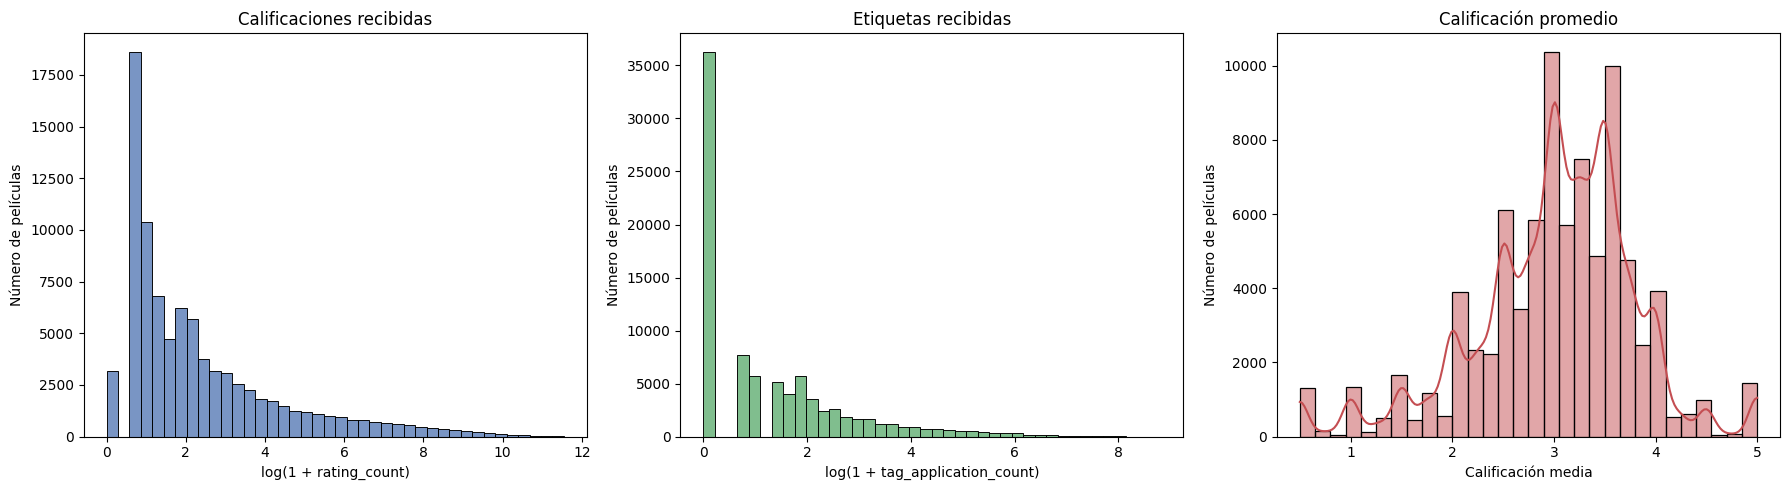

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================
# FORMA ESTADÍSTICA
# =====================================================

count_vars = [
    "rating_count",
    "rating_users",
    "tag_application_count",
    "non_null_tag_count",
    "distinct_tags",
    "tag_users"
]

shape_rows = []

for c in count_vars + ["rating_mean"]:

    if c not in movies.columns:
        continue

    s = pd.to_numeric(movies[c], errors="coerce").dropna()

    if c == "rating_mean":
        s = s[movies.loc[s.index, "rating_count"] > 0]

    skew = (
        s.skew()
        if len(s) > 2 and s.nunique() > 2
        else np.nan
    )

    kurt = (
        s.kurt()
        if len(s) > 3 and s.nunique() > 3
        else np.nan
    )

    shape_rows.append({
        "Variable": c,
        "Observaciones": len(s),
        "% Ceros": 100 * (s == 0).mean(),
        "Asimetría": skew,
        "Dirección": (
            "Derecha"
            if pd.notna(skew) and skew > 0
            else "Izquierda"
            if pd.notna(skew) and skew < 0
            else "Simétrica"
        ),
        "Curtosis": kurt
    })

shape = pd.DataFrame(shape_rows)

# =====================================================
# TABLA RESUMEN
# =====================================================

display(
    shape.round({
        "% Ceros": 2,
        "Asimetría": 3,
        "Curtosis": 3
    })
)

# =====================================================
# MOMENTOS PONDERADOS DE LAS CALIFICACIONES
# =====================================================

if all(x in globals() for x in ["v", "w", "mean_event"]):

    mu = mean_event

    m2 = np.average((v - mu) ** 2, weights=w)
    m3 = np.average((v - mu) ** 3, weights=w)
    m4 = np.average((v - mu) ** 4, weights=w)

    skew_event = m3 / m2**1.5 if m2 > 0 else np.nan
    kurt_event = m4 / m2**2 - 3 if m2 > 0 else np.nan

    print(
        f"Asimetría ponderada de calificaciones: "
        f"{skew_event:.3f}"
    )

    print(
        f"Exceso de curtosis ponderado: "
        f"{kurt_event:.3f}"
    )

# =====================================================
# VISUALIZACIONES
# =====================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

# -------------------------
# Rating count
# -------------------------
if "rating_count" in movies.columns:

    sns.histplot(
        np.log1p(movies["rating_count"]),
        bins=40,
        color="#4C72B0",
        ax=axes[0]
    )

    axes[0].set_title(
        "Calificaciones recibidas"
    )
    axes[0].set_xlabel(
        "log(1 + rating_count)"
    )
    axes[0].set_ylabel(
        "Número de películas"
    )

# -------------------------
# Tag count
# -------------------------
if "tag_application_count" in movies.columns:

    sns.histplot(
        np.log1p(movies["tag_application_count"]),
        bins=40,
        color="#55A868",
        ax=axes[1]
    )

    axes[1].set_title(
        "Etiquetas recibidas"
    )
    axes[1].set_xlabel(
        "log(1 + tag_application_count)"
    )
    axes[1].set_ylabel(
        "Número de películas"
    )

# -------------------------
# Rating mean
# -------------------------
if {
    "rating_mean",
    "rating_count"
}.issubset(movies.columns):

    sns.histplot(
        movies.loc[
            movies["rating_count"] > 0,
            "rating_mean"
        ],
        bins=30,
        kde=True,
        color="#C44E52",
        ax=axes[2]
    )

    axes[2].set_title(
        "Calificación promedio"
    )
    axes[2].set_xlabel(
        "Calificación media"
    )
    axes[2].set_ylabel(
        "Número de películas"
    )

plt.tight_layout()
plt.show()

**Interpretación:** Las variables asociadas a interacciones presentan una marcada asimetría positiva y valores elevados de curtosis, lo que indica que la mayoría de las películas recibe una cantidad reducida de interacciones, mientras que un grupo pequeño concentra volúmenes excepcionalmente altos de actividad. Este comportamiento sugiere una distribución desigual de la participación de los usuarios dentro del catálogo.

Por otro lado, la calificación promedio de las películas muestra una ligera asimetría negativa, lo que indica una mayor concentración de películas con valoraciones medias relativamente altas que con valoraciones bajas. Este patrón también se observa en la distribución de las calificaciones individuales de los usuarios, donde las puntuaciones favorables son más frecuentes que las desfavorables.

En conjunto, los resultados muestran que la actividad de los usuarios se concentra en un subconjunto reducido de películas, mientras que las valoraciones tienden a situarse predominantemente en rangos positivos.

**Limitaciones:** 
- La asimetría y la curtosis describen la forma general de las distribuciones, pero no explican las causas que generan dichos patrones.
- Los valores extremos pueden influir significativamente en estos estadísticos, especialmente en variables con distribuciones altamente concentradas.
- Las conclusiones se basan en la actividad registrada en el conjunto de datos analizado y no necesariamente representan el comportamiento de todos los usuarios o plataformas de recomendación.

## 6. Valores atípicos: detección, investigación y decisión

Se aplica la regla de Tukey `[Q1−1.5·RIQ, Q3+1.5·RIQ]`. Para datos muy concentrados en cero, RIQ puede ser cero y señalar muchas observaciones válidas. También se revisan los percentiles 95, 99 y 99.9. No se eliminan automáticamente películas populares ni títulos con pocas evaluaciones: la popularidad extrema puede ser genuina. Para puntuaciones individuales, 0.5 y 5 son límites válidos, no errores por sí mismos.


In [30]:
# 8. DETECCIÓN DE ATÍPICOS EN VARIABLES DE ACTIVIDAD
outlier_rows=[]
for c in count_vars:
    s=movies[c].dropna()
    q1,q3=s.quantile([.25,.75]); iqr=q3-q1; lo=max(0, q1-1.5*iqr); hi=q3+1.5*iqr
    outlier_rows.append({"variable":c,"q1":q1,"q3":q3,"IQR":iqr,
                         "limite_inferior":lo,"limite_superior":hi,"n_fuera":int(((s<lo)|(s>hi)).sum()),
                         "pct_fuera":100*((s<lo)|(s>hi)).mean(),
                         "p95":s.quantile(.95),"p99":s.quantile(.99),"p999":s.quantile(.999),
                         "maximo":s.max(),"IQR_cero":iqr==0})
outliers=pd.DataFrame(outlier_rows)
display(outliers)
print("Casos de máxima actividad para investigar; no se excluyen:")
display(movies.nlargest(12,"rating_count")[["movieId","title_clean","rating_count","rating_mean","tag_application_count"]])
print("Casos con >=100 evaluaciones y dispersión interna más alta:")
display(movies.loc[movies["rating_count"]>=100].nlargest(10,"rating_std")[["movieId","title_clean","rating_count","rating_mean","rating_std"]])

# Comprobar reglas de negocio antes de considerar un dato anómalo como error.
checks = {
    "conteos_negativos": int((movies[count_vars]<0).sum().sum()),
    "rating_mean_fuera_escala": int(((movies["rating_mean"].notna()) & ~movies["rating_mean"].between(0.5,5)).sum()),
    "media_sin_votos": int(((movies["rating_count"]==0)&movies["rating_mean"].notna()).sum()),
    "std_sin_al_menos_dos_votos": int(((movies["rating_count"]<2)&movies["rating_std"].notna()).sum()),
    "usuarios_mayores_que_calificaciones": int((movies["rating_users"]>movies["rating_count"]).sum()),
}
display(pd.Series(checks, name="incidencias"))

,variable,q1,q3,IQR,limite_inferior,limite_superior,n_fuera,pct_fuera,p95,p99,p999,maximo,IQR_cero
0,rating_count,2.0000,23.0000,21.0000,0,54.5000,15437,17.6252,"1,006.6000","8,877.8000","37,690.3440",102929,False
1,rating_users,2.0000,23.0000,21.0000,0,54.5000,15437,17.6252,"1,006.6000","8,877.8000","37,690.3440",102929,False
2,tag_application_count,0.0000,7.0000,7.0000,0,17.5000,12266,14.0047,85.0000,436.0000,"1,674.7280",6697,False
3,non_null_tag_count,0.0000,7.0000,7.0000,0,17.5000,12265,14.0035,85.0000,436.0000,"1,674.7280",6697,False
4,distinct_tags,0.0000,7.0000,7.0000,0,17.5000,10647,12.1562,50.0000,243.1600,519.0000,1111,False
5,tag_users,0.0000,2.0000,2.0000,0,5.0000,9008,10.2849,14.0000,71.0000,256.6640,2007,False


Casos de máxima actividad para investigar; no se excluyen:


,movieId,title_clean,rating_count,rating_mean,tag_application_count
314,318,"Shawshank Redemption, The",102929,4.4046,4892
351,356,Forrest Gump,100296,4.0527,3581
292,296,Pulp Fiction,98409,4.1970,6697
2480,2571,"Matrix, The",93808,4.1564,5722
585,593,"Silence of the Lambs, The",90330,4.1484,3469
257,260,Star Wars: Episode IV - A New Hope,85010,4.0998,6519
2867,2959,Fight Club,77332,4.2288,5532
475,480,Jurassic Park,75233,3.6986,1510
522,527,Schindler's List,73849,4.2370,2059
4888,4993,"Lord of the Rings: The Fellowship of the Ring,...",73122,4.0921,2550


Casos con >=100 evaluaciones y dispersión interna más alta:


,movieId,title_clean,rating_count,rating_mean,rating_std
1277,1311,Santa with Muscles,163,2.5521,1.7075
14392,74754,"Room, The",1179,2.4822,1.6428
21478,110603,God's Not Dead,241,2.4108,1.6277
12322,59295,Expelled: No Intelligence Allowed,166,2.0964,1.5963
11344,50703,"Secret, The",204,2.3186,1.5738
1382,1421,Grateful Dead,190,3.0421,1.5654
29196,133123,Barbie as The Princess & the Pauper,142,3.2817,1.5419
1347,1383,Adrenalin: Fear the Rush,149,2.2517,1.5264
52263,183589,Fifty Shades Freed,394,2.4987,1.5206
13101,66659,Tyler Perry's Madea Goes to Jail,142,2.5634,1.5134


conteos_negativos                      0
rating_mean_fuera_escala               0
media_sin_votos                        0
std_sin_al_menos_dos_votos             0
usuarios_mayores_que_calificaciones    0
Name: incidencias, dtype: int64

## 7. Calidad de datos y patrones de faltantes (BORRAR)
Se evalúa número y porcentaje de nulos por variable. La tabla `column_quality` proviene de las fuentes **anteriores** a la consolidación y se muestra aparte: no se debe comparar directamente su denominador con el consolidado.


In [31]:
# 9. FALTANTES POR COLUMNA Y PATRONES CONJUNTOS
missing = pd.DataFrame({"variable":movies.columns,"faltantes":movies.isna().sum().values,
                        "pct_faltantes":movies.isna().mean().values*100,
                        "dtype":movies.dtypes.astype(str).values}).sort_values("faltantes",ascending=False)
display(missing)
print("Diagnóstico de faltantes estructurales en medidas de rating:")
display(pd.crosstab(movies["rating_count"].clip(upper=2).map({0:"0 evaluaciones",1:"1 evaluación",2:"2+ evaluaciones"}),
                    movies["rating_std"].isna(), rownames=["actividad"],colnames=["rating_std ausente"], margins=True))
print("Patrones combinados de ausencia: IDs externos y medias de rating")
cols = ["imdbId","tmdbId","rating_mean","rating_std"]
patterns = movies[cols].isna().rename(columns=lambda c:c+"_nulo")
display(patterns.value_counts(dropna=False).rename("peliculas").reset_index().head(20))
print("Comparación cobertura de TMDb según actividad:")
display(pd.crosstab(movies["has_ratings"], movies["tmdbId"].isna(), normalize="index"))
print("Informe de calidad preintegración:")
display(tables["column_quality"])
print("Resultados de validación y referencial:")
display(tables["post_validation"])
display(tables["referential_integrity"])

,variable,faltantes,pct_faltantes,dtype
8,rating_std,21760,24.8444,float64
10,rating_max,3153,3.5999,float64
7,rating_mean,3153,3.5999,float64
9,rating_min,3153,3.5999,float64
2,year,617,0.7045,float64
5,tmdbId,124,0.1416,float64
1,title_clean,1,0.0011,str
0,movieId,0,0.0000,int64
3,genres,0,0.0000,str
4,imdbId,0,0.0000,int64


Diagnóstico de faltantes estructurales en medidas de rating:


rating_std ausente,False,True,All
actividad,,,
0 evaluaciones,0,3153,3153
1 evaluación,0,18607,18607
2+ evaluaciones,65825,0,65825
All,65825,21760,87585


Patrones combinados de ausencia: IDs externos y medias de rating


,imdbId_nulo,tmdbId_nulo,rating_mean_nulo,rating_std_nulo,peliculas
0,False,False,False,False,65735
1,False,False,False,True,18575
2,False,False,True,True,3151
3,False,True,False,False,90
4,False,True,False,True,32
5,False,True,True,True,2


Comparación cobertura de TMDb según actividad:


... (2 outputs left out)

,dataset,column,dtype,non_null,nulls,null_pct,unique_non_null
0,movies,movieId,int32,87585,0,0.0000,87585
1,movies,title,string,87585,0,0.0000,87382
2,movies,genres,string,87585,0,0.0000,1798
3,ratings,userId,int32,32000204,0,0.0000,200948
4,ratings,movieId,int32,32000204,0,0.0000,84432
5,ratings,rating,float32,32000204,0,0.0000,10
6,ratings,timestamp,int64,32000204,0,0.0000,25976523
7,tags,userId,int32,2000072,0,0.0000,15848
8,tags,movieId,int32,2000072,0,0.0000,51323
9,tags,tag,string,2000055,17,0.0008,140979


Resultados de validación y referencial:


,test,passed
0,movieId único en movies_consolidated,True
1,Se preservó el total de películas,True
2,Combinación movieId-genre única,True
3,Géneros vinculados a películas existentes,True
4,Agregado de ratings reconcilia con ratings ori...,True
5,Agregado de tags reconcilia con tags original,True


,child_table,distinct_movie_ids,ids_found_in_movies,orphan_movie_ids
0,ratings,84432,84432,0
1,tags,51323,51323,0
2,links,87585,87585,0


## 8. Relaciones bivariadas, asociaciones y correlaciones

Se comparan métricas por película, nunca IDs. Las variables `rating_count` y `rating_users` pueden ser prácticamente equivalentes por diseño: una correlación elevada sería estructural, no un hallazgo independiente. Se omiten variables con varianza cero.

Las medias de calificación se correlacionan sólo entre películas con evaluaciones y se repite el análisis restringiendo a **≥100 evaluaciones**, porque una nota calculada con un voto tiene incertidumbre muy distinta de otra calculada con miles. Los resultados son descriptivos, no inferenciales ni causales.

In [32]:
# 10. CORRELACIONES DE VARIABLES DE ACTIVIDAD Y PUNTUACIÓN
variables = ["rating_count","tag_application_count","distinct_tags","tag_users","rating_mean","rating_std"]
full = movies.loc[movies["rating_count"]>0,variables].copy()
restricted = movies.loc[movies["rating_count"]>=100,variables].copy()
for name, subset in [("Películas con al menos 1 evaluación",full),("Películas con al menos 100 evaluaciones",restricted)]:
    print("\n",name,"n=",len(subset))
    print("Pearson:")
    display(subset.corr(method="pearson"))
    print("Spearman:")
    display(subset.corr(method="spearman"))

# N de observaciones completas para pares seleccionados (correlación sin n puede engañar).
pairs = [("rating_count","tag_application_count"),("rating_count","rating_mean"),
         ("rating_mean","rating_std"),("tag_application_count","distinct_tags")]
correlation_rows=[]
for filt, sub in [("n>=1",full),("n>=100",restricted)]:
    for a,b in pairs:
        z=sub[[a,b]].dropna()
        correlation_rows.append({"muestra":filt,"variable_x":a,"variable_y":b,"n_pares":len(z),
                                 "pearson":z[a].corr(z[b],method="pearson"),
                                 "spearman":z[a].corr(z[b],method="spearman")})
correlation_summary=pd.DataFrame(correlation_rows)
display(correlation_summary)
print("Correlaciones sensibles al tamaño muestral, a la selección de películas y a la distribución sesgada.")


 Películas con al menos 1 evaluación n= 84432
Pearson:


,rating_count,tag_application_count,distinct_tags,tag_users,rating_mean,rating_std
rating_count,1.0000,0.7689,0.5287,0.8381,0.0976,-0.0045
tag_application_count,0.7689,1.0000,0.7637,0.9332,0.1098,-0.0040
distinct_tags,0.5287,0.7637,1.0000,0.5987,0.1082,0.0045
tag_users,0.8381,0.9332,0.5987,1.0000,0.1198,-0.0056
rating_mean,0.0976,0.1098,0.1082,0.1198,1.0000,-0.1683
rating_std,-0.0045,-0.0040,0.0045,-0.0056,-0.1683,1.0000


Spearman:


,rating_count,tag_application_count,distinct_tags,tag_users,rating_mean,rating_std
rating_count,1.0000,0.6802,0.6737,0.7107,0.1549,0.1801
tag_application_count,0.6802,1.0000,0.9988,0.9570,0.1400,0.0579
distinct_tags,0.6737,0.9988,1.0000,0.9506,0.1371,0.0570
tag_users,0.7107,0.9570,0.9506,1.0000,0.1497,0.0580
rating_mean,0.1549,0.1400,0.1371,0.1497,1.0000,-0.2402
rating_std,0.1801,0.0579,0.0570,0.0580,-0.2402,1.0000



 Películas con al menos 100 evaluaciones n= 12191
Pearson:


,rating_count,tag_application_count,distinct_tags,tag_users,rating_mean,rating_std
rating_count,1.0000,0.7400,0.4676,0.8150,0.2135,-0.0875
tag_application_count,0.7400,1.0000,0.7269,0.9271,0.2500,-0.0965
distinct_tags,0.4676,0.7269,1.0000,0.5343,0.1751,-0.0564
tag_users,0.8150,0.9271,0.5343,1.0000,0.2768,-0.1168
rating_mean,0.2135,0.2500,0.1751,0.2768,1.0000,-0.5045
rating_std,-0.0875,-0.0965,-0.0564,-0.1168,-0.5045,1.0000


Spearman:


,rating_count,tag_application_count,distinct_tags,tag_users,rating_mean,rating_std
rating_count,1.0000,0.6233,0.5521,0.7520,0.1913,-0.1040
tag_application_count,0.6233,1.0000,0.9675,0.8534,0.3028,-0.1459
distinct_tags,0.5521,0.9675,1.0000,0.7518,0.2713,-0.1330
tag_users,0.7520,0.8534,0.7518,1.0000,0.3577,-0.1905
rating_mean,0.1913,0.3028,0.2713,0.3577,1.0000,-0.5135
rating_std,-0.1040,-0.1459,-0.1330,-0.1905,-0.5135,1.0000


,muestra,variable_x,variable_y,n_pares,pearson,spearman
0,n>=1,rating_count,tag_application_count,84432,0.7689,0.6802
1,n>=1,rating_count,rating_mean,84432,0.0976,0.1549
2,n>=1,rating_mean,rating_std,65825,-0.1683,-0.2402
3,n>=1,tag_application_count,distinct_tags,84432,0.7637,0.9988
4,n>=100,rating_count,tag_application_count,12191,0.7400,0.6233
5,n>=100,rating_count,rating_mean,12191,0.2135,0.1913
6,n>=100,rating_mean,rating_std,12191,-0.5045,-0.5135
7,n>=100,tag_application_count,distinct_tags,12191,0.7269,0.9675


Correlaciones sensibles al tamaño muestral, a la selección de películas y a la distribución sesgada.


### Asociación entre categorías y comportamiento por género
Se compara la cobertura de evaluaciones entre géneros mediante tasas. Para medias de puntuación, cada película se cuenta una vez **dentro de cada género** y se restringe a títulos con ≥100 votos; como las categorías se superponen, las filas no representan grupos independientes. Se muestra también mediana para robustez.

In [33]:
# 11. ASOCIACIONES CATEGÓRICAS Y COMPARACIÓN MULTILABEL
joint = pd.crosstab(movies["has_ratings"],movies["has_tags"],margins=True)
display(joint)
display(pd.crosstab(movies["has_ratings"],movies["has_tags"],normalize="index")*100)
per_genre = movie_genres.merge(
    movies[["movieId","rating_count","rating_mean","has_ratings","tag_application_count"]],
    on="movieId",how="left",validate="many_to_many")
genre_summary = per_genre.groupby("genre").agg(
    peliculas=("movieId","nunique"),
    pct_con_evaluaciones=("has_ratings",lambda x:100*x.mean()),
    mediana_evaluaciones=("rating_count","median"),
    media_evaluaciones=("rating_count","mean"),
    mediana_etiquetas=("tag_application_count","median"))
eligible = per_genre.loc[per_genre["rating_count"]>=100]
rating_genre = eligible.groupby("genre").agg(
    peliculas_con_100_votos=("movieId","nunique"),
    media_puntuacion_por_pelicula=("rating_mean","mean"),
    mediana_puntuacion_por_pelicula=("rating_mean","median"))
genre_summary=genre_summary.join(rating_genre)
display(genre_summary.sort_values("peliculas",ascending=False))
print("Porcentaje sobre catálogo por género NO suma 100%; pertenencias múltiples.")
print("No se calculan correlaciones entre nombres de géneros e IDs numéricos.")

has_tags,False,True,All
has_ratings,,,
False,0,3153,3153
True,36262,48170,84432
All,36262,51323,87585


has_tags,False,True
has_ratings,,
False,0.0000,100.0000
True,42.9482,57.0518


,peliculas,pct_con_evaluaciones,mediana_evaluaciones,media_evaluaciones,mediana_etiquetas,peliculas_con_100_votos,media_puntuacion_por_pelicula,mediana_puntuacion_por_pelicula
genre,,,,,,,,
Drama,41255,96.2477,4.0000,340.0502,2.0000,5819,3.4516,3.5112
Comedy,23124,97.0766,6.0000,484.6448,2.0000,4231,3.1927,3.2460
Thriller,11823,97.7332,7.0000,734.1169,3.0000,2498,3.2274,3.2517
Romance,10369,96.9042,6.0000,532.8011,2.0000,1919,3.3585,3.4161
Action,9668,96.1523,8.0000,999.7117,3.0000,2111,3.1522,3.1899
Documentary,9363,97.2231,3.0000,45.6427,1.0000,547,3.6476,3.7202
Horror,8654,97.8507,6.0000,287.9957,3.0000,1357,2.9776,3.0322
Crime,6976,96.1009,7.0000,770.2195,3.0000,1469,3.3541,3.4105
Adventure,5402,95.4461,10.0000,"1,405.1318",4.0000,1458,3.2091,3.2628


Porcentaje sobre catálogo por género NO suma 100%; pertenencias múltiples.
No se calculan correlaciones entre nombres de géneros e IDs numéricos.


## 9. Conclusiones (BORRAR)
Se redacta un resumen a partir de lo calculado.

In [34]:
# 12. SÍNTESIS AUTOMÁTICA DE RESULTADOS
n_movies=len(movies)
n_rated=int(movies["has_ratings"].sum())
n_tagged=int(movies["has_tags"].sum())
median_v=float(movies["rating_count"].median())
mean_v=float(movies["rating_count"].mean())
mode_rating=float(rd.loc[rd["frequency"].idxmax(),"rating"])
rank_corr=correlation_summary.query('muestra == "n>=100" and variable_x == "rating_count" and variable_y == "rating_mean"')["spearman"].iloc[0]
most_genre=genre_summary["peliculas"].idxmax()
print("¿QUÉ REPRESENTAN LOS REGISTROS MÁS IMPORTANTES?")
print(f"• Catálogo: {n_movies:,} películas, {n_rated:,} con evaluaciones y {n_tagged:,} con etiquetas.")
print(f"• Distribución: {N:,} eventos de rating; puntuación modal {mode_rating:g} y media por evento {mean_event:.3f}.")
print("• Las películas con más eventos documentan concentración de actividad; sin eventos, no se puede estimar opinión.")
print("\n¿QUÉ VARIABLES SE TIENEN?")
print(f"• {len(movies.columns)} columnas de catálogo: identificadores y etiquetas nominales, flags dicotómicos, conteos de razón y resúmenes de rating.")
print("• Géneros: variable nominal multilabel; rating original: ordinal discreta (intervalo aproximado para promedios).")
print("\n¿QUÉ PATRONES SE DETECTARON?")
print(f"• Votos por película: media {mean_v:.2f} y mediana {median_v:.2f}; la diferencia indica concentración de actividad." )
print(f"• Género con mayor presencia: {most_genre} ({int(genre_summary.loc[most_genre,'peliculas']):,} películas).")
print(f"• Asociación monotónica votos–media con >=100 votos (Spearman): {rank_corr:.3f}.")
print(f"• Se localizaron nulos en {int((missing['faltantes']>0).sum())} columnas, con diagnóstico de ausencia estructural y cobertura.")
print("• Los outliers se conservan, sujetos a revisión de reglas de negocio; no hay recodificación automática.")
print("\nLIMITACIONES")
print("• Sin datos originales de usuario y fecha: no se evalúan efectos temporales, cohortes o dependencia intrausuario.")
print("• Un género no es exclusivo y una correlación no demuestra causalidad.")

¿QUÉ REPRESENTAN LOS REGISTROS MÁS IMPORTANTES?
• Catálogo: 87,585 películas, 84,432 con evaluaciones y 51,323 con etiquetas.
• Distribución: 32,000,204 eventos de rating; puntuación modal 4 y media por evento 3.540.
• Las películas con más eventos documentan concentración de actividad; sin eventos, no se puede estimar opinión.

¿QUÉ VARIABLES SE TIENEN?
• 20 columnas de catálogo: identificadores y etiquetas nominales, flags dicotómicos, conteos de razón y resúmenes de rating.
• Géneros: variable nominal multilabel; rating original: ordinal discreta (intervalo aproximado para promedios).

¿QUÉ PATRONES SE DETECTARON?
• Votos por película: media 365.36 y mediana 5.00; la diferencia indica concentración de actividad.
• Género con mayor presencia: Drama (41,255 películas).
• Asociación monotónica votos–media con >=100 votos (Spearman): 0.191.
• Se localizaron nulos en 7 columnas, con diagnóstico de ausencia estructural y cobertura.
• Los outliers se conservan, sujetos a revisión de reglas

## Pruebas estadísticas e inferencia

Hasta este punto, el análisis exploratorio de datos (EDA) permitió identificar patrones relevantes en las calificaciones de las películas, las diferencias entre géneros y el posible efecto de la popularidad sobre la valoración media. Sin embargo, las tendencias observadas visualmente no son suficientes para concluir si dichas diferencias reflejan comportamientos sistemáticos de la población o si podrían atribuirse al azar muestral.

Por ello, esta sección incorpora herramientas de estadística inferencial que permiten contrastar formalmente las hipótesis planteadas durante el análisis exploratorio. El objetivo es determinar si las diferencias observadas son estadísticamente significativas, identificar qué grupos las generan y evaluar la magnitud práctica de los efectos encontrados.

Las pruebas seleccionadas responden a distintos objetivos analíticos:

- **ANOVA, Levene y Kruskal-Wallis** permiten evaluar si existen diferencias globales en las calificaciones medias entre géneros cinematográficos, verificando además los supuestos de homogeneidad y considerando alternativas no paramétricas cuando resulta necesario.
- **Tukey HSD** complementa el análisis anterior identificando específicamente qué pares de géneros presentan diferencias significativas.
- **Mann-Whitney U y Welch t-test** comparan las calificaciones de películas populares y no populares mediante enfoques robustos tanto para distribuciones no normales como para varianzas desiguales.
- **Correlación de Spearman** cuantifica la asociación monotónica entre el volumen de calificaciones y la valoración promedio de una película.
- **Chi-cuadrado con corrección de Bonferroni** examina si la distribución de películas populares depende del género al que pertenecen, controlando el incremento del error por comparaciones múltiples.

En conjunto, estas pruebas transforman los hallazgos descriptivos del EDA en evidencia estadística que permite sustentar o rechazar las hipótesis del estudio con un criterio objetivo y reproducible.

In [55]:
# Dependencias estadísticas y configuración
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

try:
    from scipy.stats import tukey_hsd
except ImportError:
    tukey_hsd = None

plt.rcParams["figure.figsize"] = (10, 5)
alpha = 0.05

# Tabla base para análisis por película y género
per_movie = movies[["movieId", "rating_count", "rating_mean"]].merge(
    movie_genres,
    on="movieId",
    how="inner",
    validate="many_to_many",
)
per_movie = per_movie.dropna(subset=["rating_mean", "rating_count"])
print(f"Películas-género analizadas: {len(per_movie):,}")
print(f"Películas únicas con rating: {per_movie['movieId'].nunique():,}")
print(f"Géneros: {per_movie['genre'].nunique()}")
# Películas-género analizadas: 154,170
# Películas únicas con rating: 87,585
# Géneros: 19


Películas-género analizadas: 149,285
Películas únicas con rating: 84,432
Géneros: 20


### 1. ANOVA y comparaciones post hoc por género

#### ¿Las calificaciones medias de las películas difieren entre los distintos géneros cinematográficos?

Esta pregunta busca determinar si las diferencias observadas durante el análisis exploratorio reflejan variaciones reales entre géneros o si pueden atribuirse al azar muestral.

Evaluar si existen diferencias estadísticamente significativas en la variable `rating_mean` entre los 19 géneros cinematográficos analizados y, en caso afirmativo, identificar qué grupos contribuyen a dichas diferencias.

La unidad de análisis corresponde a una película, representada por su calificación media (`rating_mean`), considerando su pertenencia a uno o más géneros.

Para responder esta pregunta se utiliza una batería de pruebas complementarias:

- **ANOVA de una vía** permite determinar si existen diferencias globales entre las medias de los géneros.
- **Levene** verifica si las varianzas de los grupos pueden considerarse homogéneas, uno de los supuestos principales del ANOVA.
- **Kruskal-Wallis** sirve como alternativa no paramétrica cuando los supuestos clásicos pueden verse comprometidos.
- **Eta cuadrado (η²)** cuantifica la magnitud práctica del efecto, es decir, cuánto de la variabilidad observada puede asociarse al género.
- **Tukey HSD** permite identificar específicamente qué pares de géneros presentan diferencias significativas después de encontrar evidencia global de diferencias.

En conjunto, estas pruebas permiten pasar de una comparación descriptiva a una evaluación inferencial rigurosa.

La interpretación de estas pruebas se realiza considerando los siguientes supuestos y restricciones:

- Las observaciones representan películas individuales mediante su `rating_mean`.
- Los grupos contienen un tamaño suficiente para realizar comparaciones estables.
- El ANOVA asume independencia entre observaciones, distribución aproximadamente normal dentro de cada grupo y homogeneidad de varianzas.
- Kruskal-Wallis reduce la dependencia de los supuestos de normalidad al trabajar con rangos.
- Debido a que los géneros son **multietiqueta**, una misma película puede aparecer en varios grupos, por lo que la independencia entre géneros no es estrictamente completa.

### Resumen descriptivo por género

,count,mean,median,std
genre,,,,
Documentary,"9,103",3.3397,3.5000,0.7461
Film-Noir,350,3.3227,3.3438,0.4599
IMAX,195,3.2367,3.2362,0.4248
Musical,"1,033",3.1932,3.2580,0.5032
War,"2,225",3.1736,3.2778,0.6899
Drama,"33,152",3.1166,3.2110,0.7260
Romance,"10,048",3.0904,3.1614,0.7817
Animation,"4,586",3.0581,3.1429,0.7295
Crime,"6,704",3.0227,3.0949,0.6969


### Pruebas globales

,Prueba,Estadístico,Grupos,p-valor,Decisión,Interpretación
0,ANOVA clásica,409.4276,k=20,0.000000e+00,Rechazar H₀,No todas las medias son iguales
1,Levene,69.8027,k=20,0.000000e+00,Rechazar H₀,Las varianzas no son homogéneas
2,Kruskal-Wallis,8782.2182,k=20,0.000000e+00,Rechazar H₀,No todas las distribuciones son iguales



**Tamaño de efecto (η²):** 0.0495

El género explica aproximadamente **4.95%**
de la variabilidad observada en la calificación media de las películas.


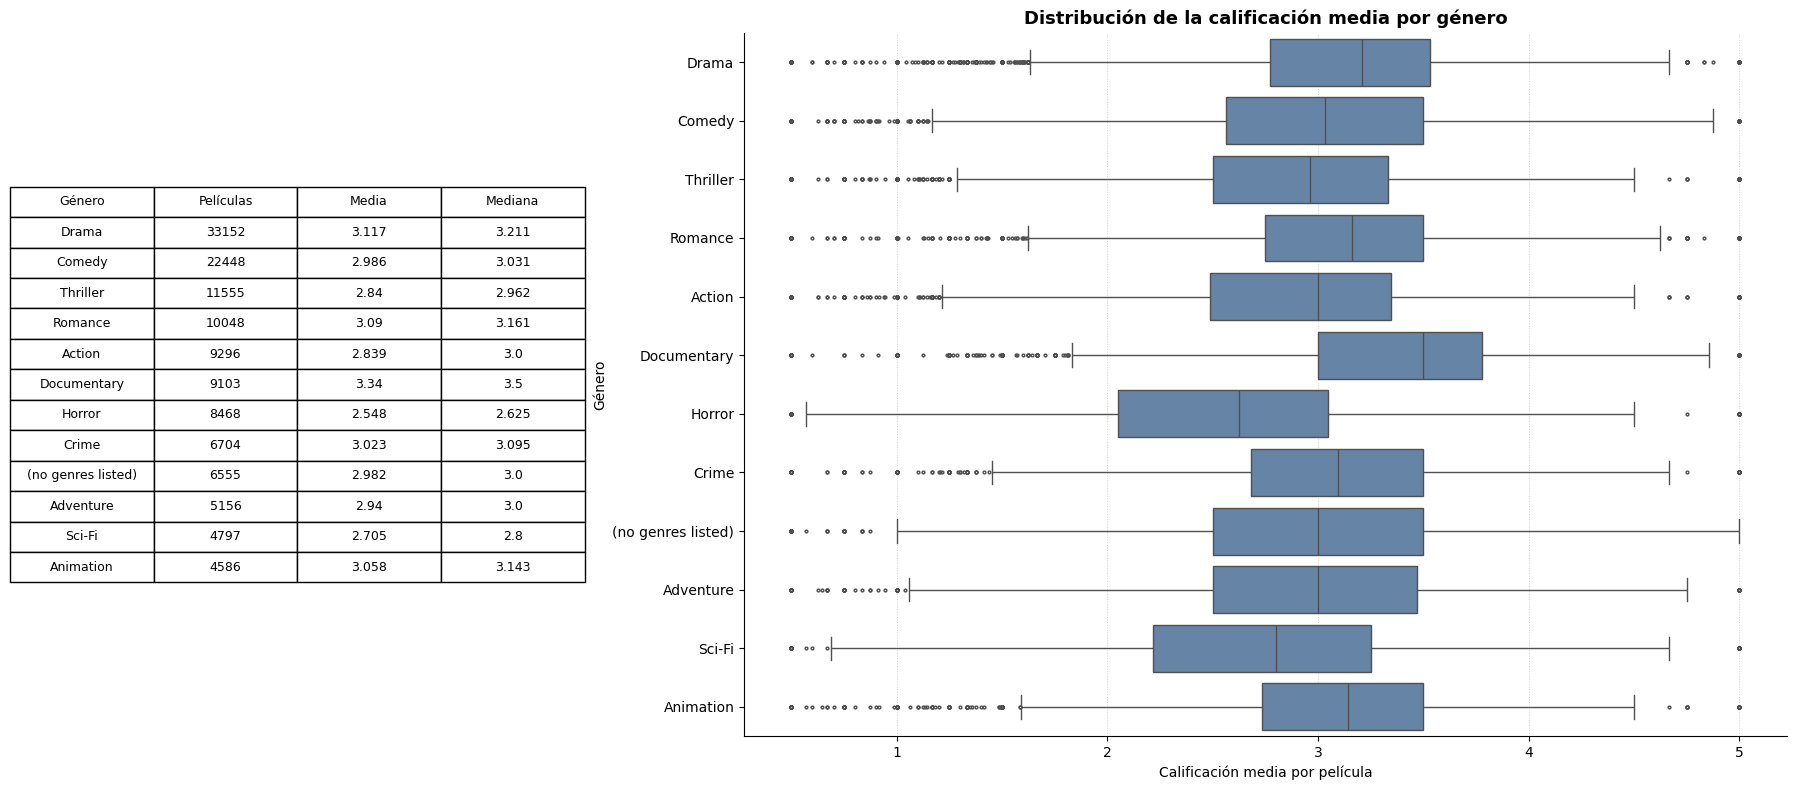

In [68]:
# ==========================================================
# ANOVA por género usando rating_mean por película
# ==========================================================

from IPython.display import display, Markdown
from matplotlib.gridspec import GridSpec

# ----------------------------------------------------------
# Estadísticos descriptivos por género
# ----------------------------------------------------------

genre_counts = (
    per_movie.groupby("genre")["rating_mean"]
    .agg(["count", "mean", "median", "std"])
)

genre_counts = genre_counts.sort_values(
    "mean",
    ascending=False
)

eligible_genres = genre_counts.index[
    genre_counts["count"] >= 30
].tolist()

groups = [
    per_movie.loc[
        per_movie["genre"] == g,
        "rating_mean"
    ]
    for g in eligible_genres
]

# ----------------------------------------------------------
# Pruebas inferenciales
# ----------------------------------------------------------

anova_f, anova_p = stats.f_oneway(*groups)

levene_stat, levene_p = stats.levene(
    *groups,
    center="median"
)

kruskal_h, kruskal_p = stats.kruskal(*groups)

# ----------------------------------------------------------
# Eta cuadrado
# ----------------------------------------------------------

all_values = pd.concat(groups)

overall_mean = all_values.mean()

ss_between = sum(
    len(g) * (g.mean() - overall_mean) ** 2
    for g in groups
)

ss_total = sum(
    (all_values - overall_mean) ** 2
)

eta_squared = ss_between / ss_total

# ----------------------------------------------------------
# Tabla de pruebas
# ----------------------------------------------------------

anova_genre_results = pd.DataFrame([
    {
        "Prueba": "ANOVA clásica",
        "Estadístico": anova_f,
        "Grupos": f"k={len(groups)}",
        "p-valor": anova_p,
        "Decisión": (
            "Rechazar H₀"
            if anova_p < alpha
            else "No rechazar H₀"
        ),
        "Interpretación": (
            "No todas las medias son iguales"
            if anova_p < alpha
            else "No hay evidencia de diferencias entre medias"
        ),
    },
    {
        "Prueba": "Levene",
        "Estadístico": levene_stat,
        "Grupos": f"k={len(groups)}",
        "p-valor": levene_p,
        "Decisión": (
            "Rechazar H₀"
            if levene_p < alpha
            else "No rechazar H₀"
        ),
        "Interpretación": (
            "Las varianzas no son homogéneas"
            if levene_p < alpha
            else "No hay evidencia de diferencias de varianza"
        ),
    },
    {
        "Prueba": "Kruskal-Wallis",
        "Estadístico": kruskal_h,
        "Grupos": f"k={len(groups)}",
        "p-valor": kruskal_p,
        "Decisión": (
            "Rechazar H₀"
            if kruskal_p < alpha
            else "No rechazar H₀"
        ),
        "Interpretación": (
            "No todas las distribuciones son iguales"
            if kruskal_p < alpha
            else "No hay evidencia de diferencias entre distribuciones"
        ),
    },
])

# ==========================================================
# TABLA DESCRIPTIVA
# ==========================================================

display(Markdown("### Resumen descriptivo por género"))

summary_table = (
    genre_counts.loc[eligible_genres]
    .round(4)
)

display(
    summary_table.style
    .format({
        "count": "{:,.0f}",
        "mean": "{:.4f}",
        "median": "{:.4f}",
        "std": "{:.4f}"
    })
    .set_properties(**{
        "text-align": "center"
    })
)


# ==========================================================
# TABLA DE RESULTADOS INFERENCIALES
# ==========================================================

display(Markdown("### Pruebas globales"))

display(
    anova_genre_results.round(6)
    .style
    .format({
        "Estadístico": "{:.4f}",
        "p-valor": "{:.6e}"
    })
    .set_properties(**{
        "text-align": "center"
    })
)

display(
    Markdown(
        f"""
**Tamaño de efecto (η²):** {eta_squared:.4f}

El género explica aproximadamente **{eta_squared*100:.2f}%**
de la variabilidad observada en la calificación media de las películas.
"""
    )
)

# ==========================================================
# TABLA + BOXPLOT
# ==========================================================

top_genres = genre_counts.nlargest(
    12,
    "count"
).index.tolist()

plot_df = per_movie[
    per_movie["genre"].isin(top_genres)
]

fig = plt.figure(figsize=(18, 8))

gs = GridSpec(
    1,
    2,
    width_ratios=[1.15, 2.4],
    figure=fig
)

# ----------------------------------------------------------
# TABLA
# ----------------------------------------------------------

ax_table = fig.add_subplot(gs[0])
ax_table.axis("off")

table_data = (
    genre_counts
    .loc[top_genres, ["count", "mean", "median"]]
    .round(3)
    .reset_index()
)

table = ax_table.table(
    cellText=table_data.values,
    colLabels=[
        "Género",
        "Películas",
        "Media",
        "Mediana"
    ],
    loc="center",
    cellLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.15, 1.6)



# ----------------------------------------------------------
# BOXPLOT
# ----------------------------------------------------------

ax_plot = fig.add_subplot(gs[1])

sns.boxplot(
    data=plot_df,
    x="rating_mean",
    y="genre",
    order=top_genres,
    orient="h",
    color="#5b84b1",
    linewidth=1,
    fliersize=2,
    ax=ax_plot
)

ax_plot.set_title(
    "Distribución de la calificación media por género",
    fontsize=13,
    fontweight="bold"
)

ax_plot.set_xlabel(
    "Calificación media por película"
)

ax_plot.set_ylabel(
    "Género"
)

ax_plot.grid(
    axis="x",
    linestyle=":",
    linewidth=0.7,
    alpha=0.6
)

ax_plot.set_axisbelow(True)

sns.despine(
    left=False,
    bottom=False
)

plt.tight_layout()
plt.show()

#### Decisiones inferenciales e interpretación

Con un nivel de significancia de α = 0.05, las tres pruebas arrojan p-valores prácticamente nulos (p < 0.001), por lo que se rechazan sus hipótesis nulas correspondientes.

- **ANOVA clásica:** se rechaza H₀, concluyendo que **no todas las medias de calificación son iguales entre los géneros**.
- **Levene:** se rechaza H₀, indicando que **las varianzas de los grupos no son homogéneas**, por lo que el supuesto de homocedasticidad del ANOVA no se cumple completamente.
- **Kruskal-Wallis:** se rechaza H₀, concluyendo que **no todas las distribuciones de calificaciones son iguales entre los géneros**.

Los resultados obtenidos muestran evidencia consistente de diferencias entre géneros. La coincidencia entre ANOVA y Kruskal-Wallis indica que las diferencias observadas son robustas independientemente del enfoque paramétrico o no paramétrico utilizado. Asimismo, el resultado de Levene sugiere que las varianzas no son homogéneas entre grupos, por lo que la evidencia aportada por Kruskal-Wallis adquiere especial relevancia como contraste complementario.

Aunque las diferencias observadas son estadísticamente significativas, el tamaño del efecto resulta relativamente moderado. El valor de **η² = 0.0485** indica que aproximadamente **el 4.85% de la variabilidad observada en las calificaciones medias puede asociarse al género cinematográfico**. En consecuencia, el género contribuye a explicar parte de las diferencias en las valoraciones, pero existen otros factores que también desempeñan un papel importante.

Desde una perspectiva descriptiva, los mayores promedios de `rating_mean` corresponden a **Documentary**, **Film-Noir** e **IMAX**, mientras que **Horror**, **Sci‑Fi** y **Action** presentan los promedios más bajos. Estos resultados deben interpretarse como diferencias promedio entre grupos y no como una clasificación absoluta de calidad cinematográfica.

Las pruebas realizadas permiten afirmar que existen diferencias globales entre géneros, pero no identifican cuáles grupos difieren específicamente entre sí. Por ello, el siguiente paso consiste en realizar comparaciones múltiples mediante **Tukey HSD**, con el fin de localizar los pares de géneros responsables de las diferencias detectadas.

**Limitaciones:**

- El tamaño de la muestra es muy grande (149,285 observaciones película–género), por lo que incluso diferencias relativamente pequeñas pueden generar p-valores extremadamente bajos.
- La pertenencia simultánea de una película a varios géneros introduce dependencias entre observaciones que no son consideradas explícitamente por el ANOVA tradicional.
- Las diferencias detectadas no implican causalidad; únicamente describen asociaciones entre género y calificación media.
- El género explica una proporción limitada de la variabilidad total (η² ≈ 4.85%), por lo que variables como el año de estreno, la popularidad, el número de valoraciones o las preferencias de los usuarios pueden tener una influencia igual o mayor.
- Los resultados globales identifican la existencia de diferencias, pero no permiten determinar qué géneros son responsables de ellas sin recurrir a análisis post hoc como **Tukey HSD**.

### ¿Qué pares de géneros cinematográficos presentan diferencias significativas en sus calificaciones medias?

Tras comprobar que existen diferencias globales entre géneros mediante ANOVA y Kruskal-Wallis, surge una pregunta más específica: identificar cuáles grupos son responsables de dichas diferencias.

Determinaremos entre qué pares de géneros existen diferencias estadísticamente significativas en la variable `rating_mean`, cuantificando además la magnitud de dichas diferencias mediante estimaciones de medias e intervalos de confianza.

El propósito no es únicamente confirmar que existen diferencias, sino localizar dónde aparecen y evaluar si son consistentes desde una perspectiva estadística.

Para ello, se empleará la prueba **Tukey HSD (Honestly Significant Difference)** como procedimiento post hoc posterior a un ANOVA global significativo.

Este método compara simultáneamente todas las combinaciones posibles de medias entre grupos y ajusta los contrastes para controlar el **error de familia (Family Wise Error Rate)**, evitando que la probabilidad de falsos positivos aumente al realizar múltiples comparaciones.

Además de los p-valores ajustados, Tukey proporciona:

- Diferencias de medias entre pares de géneros.
- Intervalos de confianza al 95%.
- Identificación explícita de las comparaciones estadísticamente significativas.

Un intervalo de confianza que no contiene el valor cero indica evidencia de una diferencia significativa entre ambos grupos.

El análisis post hoc no debe interpretarse de forma aislada, sino en conjunto con los resultados obtenidos previamente:

- **ANOVA clásica:** detectó diferencias globales entre medias.
- **Levene:** identificó heterogeneidad de varianzas entre géneros.
- **Kruskal-Wallis:** confirmó las diferencias mediante un enfoque no paramétrico.
- **Tukey HSD:** permite localizar específicamente los pares de géneros que generan esas diferencias.

Por tanto, Tukey actúa como una extensión natural del ANOVA, mientras que Kruskal-Wallis proporciona evidencia complementaria cuando los supuestos paramétricos son imperfectos.

In [37]:
# Tukey HSD post hoc
if tukey_hsd is not None and anova_p < alpha:
    tukey = tukey_hsd(*groups)
    tukey_ci = tukey.confidence_interval(confidence_level=0.95)
    tukey_rows = []
    for i in range(len(eligible_genres)):
        for j in range(i + 1, len(eligible_genres)):
            tukey_rows.append({
                "género_1": eligible_genres[i],
                "género_2": eligible_genres[j],
                "diferencia_media": tukey.statistic[i, j],
                "p_valor": tukey.pvalue[i, j],
                "intervalo_95_inf": tukey_ci.low[i, j],
                "intervalo_95_sup": tukey_ci.high[i, j],
                "significativo": bool(tukey.pvalue[i, j] < alpha),
            })
    tukey_df = pd.DataFrame(tukey_rows)
    print(f"Comparaciones post hoc: {len(tukey_df):,}; significativas: {int(tukey_df['significativo'].sum())}")
    display(tukey_df.sort_values("p_valor").head(20).round(6))
else:
    tukey_df = pd.DataFrame()
    print("Tukey HSD no ejecutado: omiso si no existe scipy compatible o si ANOVA global no rechaza H0.")


Comparaciones post hoc: 171; significativas: 141


,género_1,género_2,diferencia_media,p_valor,intervalo_95_inf,intervalo_95_sup,significativo
3,Documentary,War,0.1661,0.0000,0.1026,0.2296,True
6,Documentary,Animation,0.2816,0.0000,0.2331,0.3302,True
5,Documentary,Romance,0.2493,0.0000,0.2105,0.2882,True
4,Documentary,Drama,0.2453,0.0000,0.2141,0.2765,True
7,Documentary,Crime,0.3170,0.0000,0.2738,0.3602,True
10,Documentary,Mystery,0.3971,0.0000,0.3457,0.4485,True
9,Documentary,Fantasy,0.3963,0.0000,0.3444,0.4482,True
8,Documentary,Comedy,0.3540,0.0000,0.3207,0.3874,True
12,Documentary,Children,0.4227,0.0000,0.3736,0.4718,True
13,Documentary,Western,0.4254,0.0000,0.3504,0.5004,True


**Interpretación:** La prueba realizó **171 comparaciones por pares** entre los géneros analizados y encontró **141 diferencias estadísticamente significativas**. Esto indica que las diferencias observadas en el análisis global no se concentran en unos pocos grupos aislados, sino que aparecen de forma relativamente extendida entre numerosos géneros.

Entre los contrastes más notorios destacan:

- **Documentary** presenta una calificación media superior a **Horror** en aproximadamente **0.79 puntos**, con un intervalo de confianza del 95% completamente por encima de cero.
- **Documentary** supera a **Sci‑Fi** en aproximadamente **0.64 puntos**.
- **IMAX** supera a **Horror** en aproximadamente **0.69 puntos**.
- **Film-Noir** supera a **Thriller** en aproximadamente **0.48 puntos**.

La ausencia del valor cero en estos intervalos proporciona evidencia sólida de que las diferencias estimadas son consistentes con los datos observados.

En términos generales, los resultados muestran que géneros como **Documentary**, **Film-Noir** e **IMAX** tienden a registrar valoraciones medias superiores, mientras que géneros como **Horror**, **Sci‑Fi** y **Thriller** aparecen frecuentemente entre los grupos con valoraciones más bajas.

No obstante, el boxplot revela un importante solapamiento entre distribuciones, indicando que, aunque las medias difieran, existe una considerable variabilidad interna dentro de cada género.

**Conclusión inferencial**

Las comparaciones post hoc confirman que las diferencias globales detectadas por ANOVA no solo existen, sino que se distribuyen a través de una gran cantidad de pares de géneros. La evidencia indica que determinados géneros presentan sistemáticamente calificaciones medias más altas o más bajas que otros, aunque dichas diferencias deben interpretarse en el contexto de una elevada variabilidad dentro de los grupos.

**Limitaciones:**

- Tukey HSD se basa en el análisis de medias y hereda parcialmente los supuestos del ANOVA.
- La prueba de Levene mostró evidencia de heterogeneidad de varianzas, lo que aconseja interpretar los resultados con cautela.
- Los géneros cinematográficos son una variable multietiqueta; una misma película puede pertenecer simultáneamente a varios grupos, reduciendo la independencia estricta entre observaciones.
- El gran tamaño muestral incrementa la potencia estadística y favorece la detección de diferencias pequeñas como estadísticamente significativas.
- La significancia estadística no implica necesariamente relevancia práctica; por ello los resultados deben valorarse conjuntamente con las diferencias de medias, los intervalos de confianza y el tamaño del efecto observado en el ANOVA.
- Las comparaciones identifican asociaciones entre género y calificación, pero no permiten establecer relaciones causales.

### Comparación entre películas populares y no populares

#### ¿Las películas con mayor volumen de evaluaciones reciben calificaciones medias diferentes a las películas menos populares?

Esta pregunta busca determinar si existe una asociación entre la popularidad de una película, medida por la cantidad de evaluaciones recibidas (`rating_count`), y la valoración promedio que obtiene de los usuarios.

Compararemos las distribuciones de `rating_mean` entre películas populares y no populares para determinar si ambos grupos presentan comportamientos distintos en sus calificaciones.

Además de establecer si la diferencia es estadísticamente significativa, se busca cuantificar su dirección y magnitud para evaluar si las películas más populares tienden a recibir valoraciones más altas.


**Definición de los grupos comparados**

Con el fin de reducir la influencia de películas con muy pocas evaluaciones, el análisis se restringe a películas con al menos **100 votos**.

Posteriormente, la popularidad se define utilizando el percentil 75 de `rating_count` dentro de esta muestra:

- **Popular:** películas con `rating_count ≥ 1,845.50`.
- **No popular:** películas con `rating_count < 1,845.50`.

Esta clasificación genera:

- **3,048 películas populares**
- **9,143 películas no populares**

---

#### Método utilizado

Se emplean dos pruebas complementarias para comparar ambos grupos:

##### Mann-Whitney U (prueba principal)

Es una prueba no paramétrica que compara las posiciones o rangos de las observaciones entre dos grupos independientes.

Se utiliza como prueba principal porque:

- No requiere asumir normalidad de las distribuciones.
- Es robusta frente a asimetrías o valores extremos.
- Permite evaluar si un grupo tiende sistemáticamente a presentar valores más altos o más bajos que el otro.

##### Welch t-test (prueba de robustez)

Se utiliza como contraste complementario para comparar medias entre dos grupos sin asumir igualdad de varianzas.

Su inclusión permite verificar si la conclusión obtenida mediante Mann-Whitney se mantiene bajo un enfoque paramétrico centrado en las medias.

##### Correlación biserial de rango aproximada

Se calcula como medida de tamaño del efecto asociada a Mann-Whitney.

Su propósito es cuantificar la dirección e intensidad de la diferencia observada:

- Valores positivos indican ventaja del grupo popular.
- Valores cercanos a cero indican poca diferenciación entre grupos.
- Valores más alejados de cero representan asociaciones más intensas.

---

#### Contraste de pruebas

El análisis combina dos enfoques:

| Prueba | Propósito |
|----------|----------|
| **Mann-Whitney U** | Comparar distribuciones mediante rangos |
| **Welch t** | Comparar medias permitiendo varianzas distintas |
| **Biserial de rango** | Medir la magnitud y dirección del efecto |

La utilización simultánea de una prueba paramétrica y otra no paramétrica permite evaluar la robustez de las conclusiones.

---

Umbral del percentil 75: 1,845.50 evaluaciones
Resumen por popularidad:


,count,mean,median,std
popularidad,,,,
No popular,9143,3.2458,3.3182,0.4795
Popular (top 25%),3048,3.4464,3.5163,0.4477


,prueba,estadístico,p_valor,decisión
0,Mann-Whitney U,"17,374,599.0000",0.0000,Rechazar H0
1,Welch t (robustez),21.0437,0.0000,Rechazar H0


Biserial de rango aproximado: 0.2469


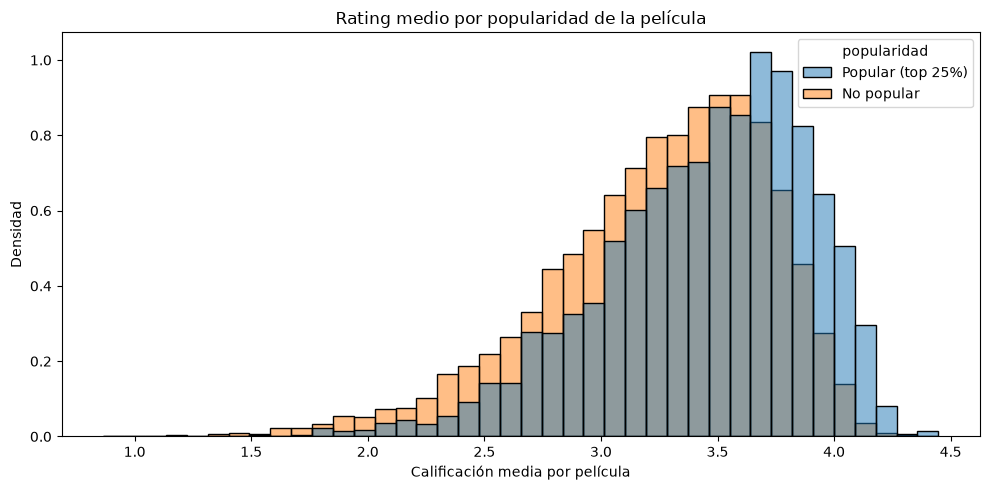

In [38]:
# Comparación popular vs no popular
rated_movies = movies[movies.rating_count >=100]\
                    .dropna(subset=["rating_mean", "rating_count"]).copy()
popular_threshold = rated_movies["rating_count"].quantile(0.75)
rated_movies["popularidad"] = np.where(
    rated_movies["rating_count"] >= popular_threshold,
    "Popular (top 25%)",
    "No popular",
)
popular = rated_movies.loc[rated_movies["popularidad"] == "Popular (top 25%)", "rating_mean"]
not_popular = rated_movies.loc[rated_movies["popularidad"] == "No popular", "rating_mean"]

mann_u, mann_p = stats.mannwhitneyu(popular, not_popular, alternative="two-sided", method="auto")
welch_t, welch_p = stats.ttest_ind(popular, not_popular, equal_var=False)
# Biserial de rango aproximado: 1 significa que popular siempre supera a no popular
rank_biserial = 2 * mann_u / (len(popular) * len(not_popular)) - 1

popularity_results = pd.DataFrame([
    {"prueba": "Mann-Whitney U", "estadístico": mann_u, "p_valor": mann_p, "decisión": "Rechazar H0" if mann_p < alpha else "No rechazar H0"},
    {"prueba": "Welch t (robustez)", "estadístico": welch_t, "p_valor": welch_p, "decisión": "Rechazar H0" if welch_p < alpha else "No rechazar H0"},
])
print(f"Umbral del percentil 75: {popular_threshold:,.2f} evaluaciones")
print("Resumen por popularidad:")
display(rated_movies.groupby("popularidad")["rating_mean"].agg(["count", "mean", "median", "std"]).round(4))
display(popularity_results.round(6))
print(f"Biserial de rango aproximado: {rank_biserial:.4f}")

sns.histplot(data=rated_movies, x="rating_mean", hue="popularidad", bins=40, stat="density", common_norm=False)
plt.title("Rating medio por popularidad de la película")
plt.xlabel("Calificación media por película")
plt.ylabel("Densidad")
plt.tight_layout()
plt.show()



#### Decisiones inferenciales

Con un nivel de significancia de α = 0.05, ambas pruebas producen p-valores menores a 0.0001.

- **Mann-Whitney U:** se rechaza H₀, concluyendo que las distribuciones de `rating_mean` difieren entre películas populares y no populares.
- **Welch t:** se rechaza H₀, concluyendo que las medias de `rating_mean` difieren entre ambos grupos.

La coincidencia entre ambas pruebas proporciona evidencia consistente de que la popularidad está asociada con diferencias observables en las calificaciones medias.

---

#### Interpretación de los resultados

Los resultados descriptivos muestran diferencias sistemáticas entre los grupos:

| Medida | No populares | Populares |
|----------|----------:|----------:|
| n | 9,143 | 3,048 |
| Media | 3.2458 | 3.4464 |
| Mediana | 3.3182 | 3.5163 |
| Desviación estándar | 0.4795 | 0.4477 |

Las películas populares presentan:

- Una media aproximadamente **0.20 puntos superior**.
- Una mediana aproximadamente **0.20 puntos superior**.
- Una dispersión ligeramente menor.

Adicionalmente, el coeficiente biserial de rango alcanza un valor de **0.2469**, lo que sugiere una asociación positiva de magnitud moderada entre popularidad y calificación media.

En términos prácticos, los resultados indican que las películas más populares tienden a ocupar posiciones más altas en la distribución de calificaciones que las películas menos populares.

La convergencia entre Mann-Whitney y Welch refuerza la estabilidad de esta conclusión.

---

#### Conclusión inferencial

La evidencia estadística indica que las películas populares reciben, en promedio, calificaciones más altas que las películas no populares dentro de la muestra analizada.

Aunque la diferencia observada no es extremadamente grande, su consistencia en medias, medianas y rangos sugiere que la popularidad se encuentra asociada a una mejor valoración promedio por parte de los usuarios.

---

#### Limitaciones

- La clasificación de popularidad depende de un umbral definido analíticamente (percentil 75) y no de una categoría inherente al catálogo.
- Los resultados describen asociaciones y no permiten establecer relaciones causales.
- Es posible que variables no observadas expliquen simultáneamente la popularidad y las calificaciones, como la calidad percibida, campañas de promoción, reconocimiento de marca, antigüedad o disponibilidad de la película.
- El tamaño de la muestra proporciona una potencia estadística muy elevada, por lo que diferencias relativamente pequeñas pueden resultar significativas.
- La popularidad se mide exclusivamente mediante volumen de evaluaciones y no considera otros indicadores potenciales de éxito o visibilidad.
- La diferencia identificada representa un patrón promedio y no implica que todas las películas populares sean mejor valoradas que todas las películas no populares.

## Análisis complementario: asociación entre volumen de evaluaciones, popularidad y género

Las pruebas anteriores permitieron identificar diferencias en las calificaciones según el género cinematográfico y la popularidad de las películas. Sin embargo, aún es necesario comprender cómo se relacionan estas variables entre sí. Para ello se incorporan análisis orientados a medir asociaciones, más que diferencias entre grupos.


#### Correlación de Spearman: volumen de votos y calificación media

**¿Las películas que reciben más evaluaciones tienden a obtener mejores calificaciones medias?**

Determinaremos si existe una asociación monotónica entre el volumen de evaluaciones (`rating_count`) y la calificación media de las películas (`rating_mean`).

El análisis busca establecer si una mayor exposición o participación de usuarios se relaciona con mejores valoraciones dentro de la plataforma.

**Método utilizado**

Se emplea la **correlación de Spearman (ρ)**, una medida no paramétrica basada en rangos que evalúa relaciones monotónicas entre variables cuantitativas.

Este método se selecciona porque:

- No requiere normalidad en las variables.
- No asume una relación lineal.
- Es robusto frente a distribuciones asimétricas.
- Permite detectar asociaciones crecientes o decrecientes aun cuando no sean lineales.

La prueba se aplica sobre las películas con al menos 100 evaluaciones para reducir la influencia de observaciones con escasa información.

**Contraste de hipótesis**

**Hipótesis nula (H₀):**

No existe asociación monotónica entre el número de evaluaciones y la calificación media (ρ = 0).

**Hipótesis alternativa (H₁):**

Existe asociación monotónica entre ambas variables (ρ ≠ 0).

**Contraste específico de la prueba**

Se utiliza exclusivamente la correlación de Spearman.

El estadístico se interpreta mediante:

- **Coeficiente rho (ρ):** mide dirección y magnitud de la asociación.
- **p-valor:** determina si la asociación observada es compatible con la hipótesis de independencia monotónica.


#### Chi-cuadrado de independencia: popularidad y género

**¿La popularidad de una película se distribuye de forma independiente de su género cinematográfico?**

Evaluaremos si determinados géneros presentan una proporción de películas populares significativamente distinta de la esperada bajo independencia.

El objetivo es identificar patrones de popularidad asociados a géneros específicos.

**Método utilizado**

Se aplica una **prueba Chi-cuadrado de independencia** utilizando tablas de contingencia 2 × 2 construidas para cada género:

- Presencia del género (Sí / No).
- Popularidad (Popular / No popular).

Debido a que se realizan múltiples contrastes simultáneamente, se incorpora una **corrección de Bonferroni** para controlar el incremento del error Tipo I.

**Contraste de hipótesis**

Para cada género analizado:

**Hipótesis nula (H₀):**

La presencia del género es independiente de la popularidad.

**Hipótesis alternativa (H₁):**

La presencia del género y la popularidad están asociadas.

**Contraste específico de pruebas**

El procedimiento combina dos componentes complementarios:

- **Chi-cuadrado de independencia:** Evalúa si las frecuencias observadas de películas populares y no populares difieren de las frecuencias esperadas bajo independencia.

- **Corrección de Bonferroni:** Ajusta los p-valores para compensar los múltiples contrastes realizados simultáneamente. Su finalidad es reducir la probabilidad de detectar asociaciones significativas por azar cuando se evalúan numerosos géneros de forma paralela.

In [39]:
# Prueba adicional: Spearman entre volumen de votos y rating medio
spearman_df = rated_movies[rated_movies["rating_count"] >= 100]
spearman_r, spearman_p = stats.spearmanr(
    spearman_df["rating_count"],
    spearman_df["rating_mean"],
)
print("Spearman formal (películas con al menos 100 votos):")
display(pd.DataFrame([{
    "prueba": "Spearman",
    "n": len(spearman_df),
    "rho": spearman_r,
    "p_valor": spearman_p,
    "decisión": "Rechazar H0" if spearman_p < alpha else "No rechazar H0",
}]).round(6))


Spearman formal (películas con al menos 100 votos):


,prueba,n,rho,p_valor,decisión
0,Spearman,12191,0.1913,0.0000,Rechazar H0


In [40]:
# Prueba adicional: chi-cuadrado popularidad × género
# Se evalúa género por género; 0.05/20 usa una aproximación conservadora de Bonferroni.
top_genres_for_test = genre_counts.nlargest(20, "count").index.tolist()
chi_rows = []
for genre_name in top_genres_for_test:
    presence = per_movie.drop_duplicates("movieId").merge(
        movie_genres[movie_genres["genre"] == genre_name][["movieId"]].assign(presencia=1),
        on="movieId",
        how="left",
    )
    presence["presencia"] = presence["presencia"].fillna(0)
    presence = presence.merge(rated_movies[["movieId", "popularidad"]], on="movieId", how="inner")
    contingency = pd.crosstab(presence["presencia"], presence["popularidad"])
    if contingency.shape == (2, 2):
        chi2, pvalue, dof, expected = stats.chi2_contingency(contingency, correction=False)
        chi_rows.append({
            "género": genre_name,
            "chi2": chi2,
            "gl": dof,
            "p_valor": pvalue,
            "p_bonferroni": min(1.0, pvalue * len(top_genres_for_test)),
            "significativo_bonferroni": pvalue * len(top_genres_for_test) < alpha,
        })

chi_df = pd.DataFrame(chi_rows)
print("Chi-cuadrado por género (popular vs no popular):")
display(chi_df.sort_values("p_bonferroni").round(6))


Chi-cuadrado por género (popular vs no popular):


,género,chi2,gl,p_valor,p_bonferroni,significativo_bonferroni
4,Action,286.4804,1,0.0000,0.0000,True
8,Adventure,232.3208,1,0.0000,0.0000,True
18,IMAX,210.7709,1,0.0000,0.0000,True
9,Sci-Fi,165.6011,1,0.0000,0.0000,True
2,Thriller,100.4837,1,0.0000,0.0000,True
5,Documentary,91.6613,1,0.0000,0.0000,True
13,Fantasy,57.0197,1,0.0000,0.0000,True
7,Crime,35.4864,1,0.0000,0.0000,True
6,Horror,21.8415,1,0.0000,0.0001,True
11,Children,20.5755,1,0.0000,0.0001,True


## Resultados e interpretación de las pruebas complementarias

### Correlación de Spearman: volumen de votos y calificación media

#### Decisión inferencial

La prueba de Spearman obtuvo:

- **ρ = 0.1913**
- **p < 0.0001**

Dado que el p-valor es inferior al nivel de significancia establecido (α = 0.05), se **rechaza H₀** y se concluye que existe evidencia estadística de una asociación monotónica entre el volumen de evaluaciones y la calificación media de las películas.

#### Interpretación de los resultados

La asociación identificada es positiva, lo que indica que las películas con una mayor cantidad de evaluaciones tienden a registrar calificaciones medias ligeramente superiores.

Sin embargo, el valor del coeficiente (**ρ = 0.1913**) muestra una relación débil. Esto implica que, aunque la asociación existe desde el punto de vista estadístico, el volumen de votos explica únicamente una pequeña parte de la variabilidad observada en las calificaciones.

En términos prácticos, las películas más votadas suelen estar algo mejor valoradas, pero la relación está lejos de ser determinante.

#### Limitaciones

- La correlación no implica causalidad.
- Una mayor cantidad de evaluaciones no necesariamente produce mejores calificaciones.
- Factores externos como notoriedad, promoción, antigüedad o disponibilidad pueden influir simultáneamente en ambas variables.
- El coeficiente resume una tendencia global y puede ocultar comportamientos particulares dentro de géneros específicos.
- El análisis se restringe a películas con al menos 100 evaluaciones, por lo que sus conclusiones no representan necesariamente a todo el catálogo.

### Chi-cuadrado de independencia: popularidad y género

#### Decisión inferencial

Tras aplicar la corrección de Bonferroni se identificaron asociaciones estadísticamente significativas entre popularidad y los siguientes géneros:

- Action
- Adventure
- IMAX
- Sci-Fi
- Thriller
- Documentary
- Fantasy
- Crime
- Horror
- Children
- Mystery
- Romance

Por otra parte:

- Drama y Comedy presentan significancia nominal, pero dejan de ser significativos después de la corrección.
- Animation, Western, Musical y Film-Noir no presentan evidencia suficiente para rechazar H₀.

En consecuencia, para varios géneros se rechaza la hipótesis de independencia y se concluye que existe una asociación estadística entre la presencia del género y la popularidad de la película.

#### Interpretación de los resultados

Los resultados indican que la distribución de películas populares no es uniforme entre géneros.

Algunos géneros aparecen con una frecuencia de popularidad significativamente distinta a la esperada bajo independencia, lo que sugiere patrones diferenciados de consumo, visibilidad o aceptación dentro de la plataforma.

No obstante, la prueba únicamente informa sobre la existencia de asociación. Aunque permite detectar géneros vinculados a perfiles de popularidad particulares, no establece la dirección ni la intensidad de dicha relación.

#### Limitaciones

- La prueba identifica asociaciones, pero no relaciones causales.
- El estadístico Chi-cuadrado no proporciona una medida directa de magnitud del efecto.
- La corrección de Bonferroni reduce falsos positivos, pero aumenta la probabilidad de falsos negativos.
- Los géneros constituyen una variable multietiqueta; una película puede pertenecer simultáneamente a varios grupos.
- La definición de popularidad depende del umbral analítico seleccionado y podría variar bajo otros criterios de clasificación.
- El análisis no identifica qué factores explican la asociación observada entre género y popularidad.

### Conclusión general

Las pruebas complementarias muestran que el volumen de evaluaciones, la popularidad y el género presentan relaciones estadísticamente detectables dentro del conjunto de datos. La correlación de Spearman indica que las películas más evaluadas tienden a recibir mejores calificaciones, aunque con una intensidad débil. Por su parte, las pruebas Chi-cuadrado evidencian que varios géneros presentan perfiles de popularidad significativamente distintos de los esperados bajo independencia.

En conjunto, estos resultados amplían la interpretación obtenida en las secciones anteriores, mostrando que las diferencias observadas en las calificaciones no dependen exclusivamente del género o de la popularidad, sino también de la interacción entre múltiples factores asociados al comportamiento de los usuarios y a las características del catálogo.

### 4. Conclusión integrada

La evidencia converge en un patrón: **las calificaciones medias no son homogéneas entre géneros ni entre niveles de popularidad**. Las mayores medias aparecen en Documentaries, Film-Noir e IMAX; las menores, en Horror, Sci-Fi y Action. Al comparar títulos populares y no populares, los populares promedian 3.4464 frente a 3.2458 y mantienen una mediana mayor.

El siguiente nivel de detalle viene de las comparaciones por pares y asociaciones adicionales:

- Tukey encuentra 141 pares significativos entre 171 posibles.
- Mann-Whitney y Welch coinciden en rechazar la igualdad entre popularidad.
- Spearman revela una relación positiva débil entre votos y calificación (`rho = 0.1913`).
- Chi-cuadrado muestra 12 géneros asociados significativamente con popularidad después de Bonferroni.

La lectura definitiva debe ser moderada. En bases de gran tamaño, la significancia es fácil de alcanzar; por eso se integran las medias, medianas, intervalos, proporción de variación y efectos de rango. Además, un género puede solaparse con otros, una calificación media puede ocultar diferencias entre usuarios y popularidad puede reflejar exposición en lugar de calidad. Las pruebas implementadas describen diferencias y asociaciones observables, pero no prueban causalidad.


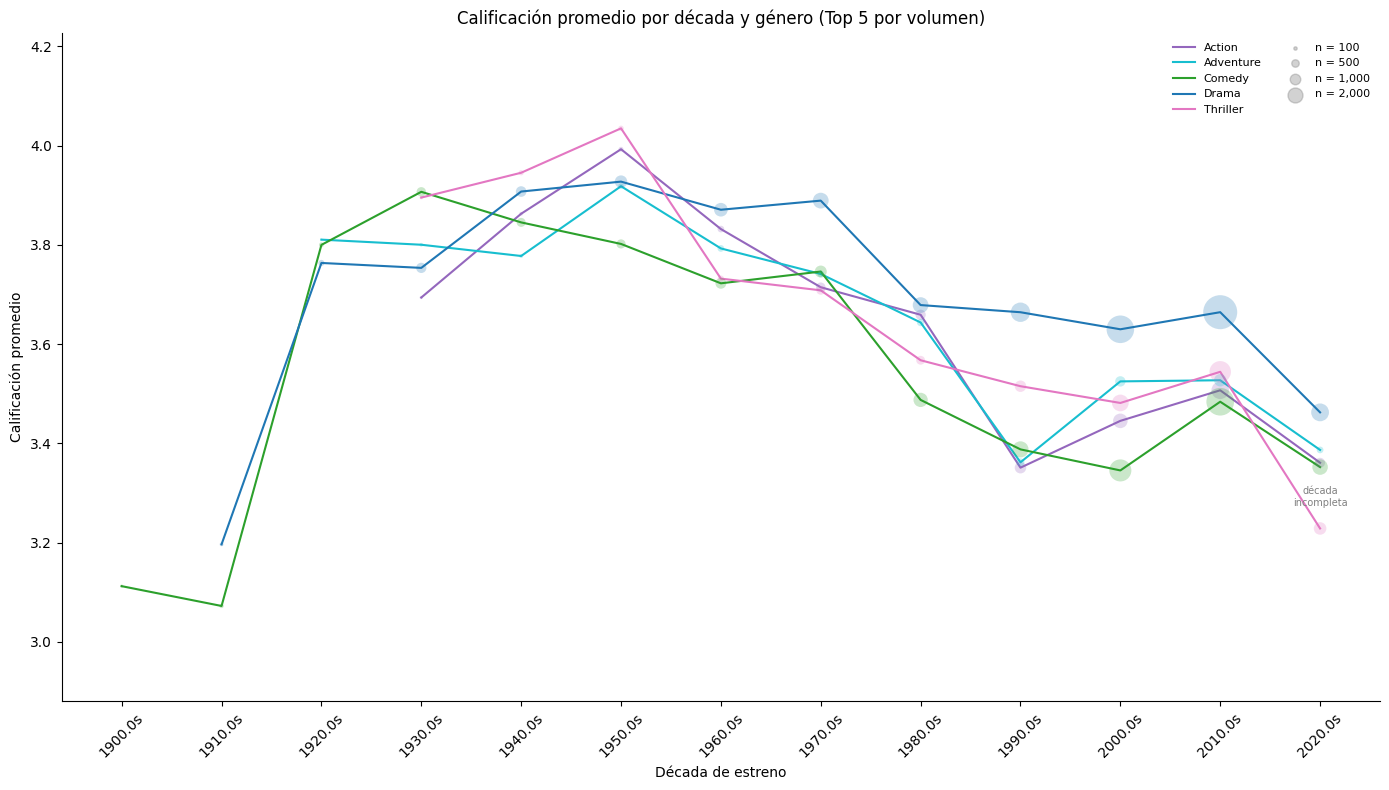

In [70]:
movies_consolidated_clean = movies.dropna(subset=["year", "rating_mean"]).copy()
movies_consolidated_clean["decada"] = (movies_consolidated_clean["year"] // 10) * 10
movies_consolidated_clean["suma"] = movies_consolidated_clean["rating_mean"] * movies_consolidated_clean["rating_count"]

import matplotlib.cm as cm

# Explotar genres (formato MovieLens: "Action|Adventure|Sci-Fi")
movies_genero = (
    movies_consolidated_clean
    .assign(genero=movies_consolidated_clean["genres"].str.split("|"))
    .explode("genero")
)
movies_genero = movies_genero[movies_genero["genero"] != "(no genres listed)"]

# Agrupación espejo a por_decada, añadiendo genero como segundo nivel
por_decada_genero = (
    movies_genero
    .groupby(["decada", "genero"])
    .agg(
        n_peliculas=("movieId",      "nunique"),
        n_calif    =("rating_count", "sum"),
        media_peliculas=("rating_mean",  "mean"),   # cada película pesa igual
        suma       =("suma",         "sum"),
    )
    .reset_index()
)
por_decada_genero["media_ponderada"] = (por_decada_genero["suma"]
                                        / por_decada_genero["n_calif"])
por_decada_genero = (por_decada_genero
                     .drop(columns="suma")
                     .sort_values(["genero", "decada"])
                     .reset_index(drop=True))

# ══════════════════════════════════════════════════════════════════
# 2. VISUALIZACIÓN
# ══════════════════════════════════════════════════════════════════

UMBRAL     = 50    # por género el conteo es menor que el global
TOP_N      = 5    # géneros a mostrar (los de mayor volumen de calificaciones)
BURBUJA_MAX = 600  # área máxima de burbuja en puntos²

# Seleccionar top géneros por volumen de calificaciones
top_generos = (
    por_decada_genero
    .groupby("genero")["n_calif"].sum()
    .nlargest(TOP_N).index.tolist()
)
datos = por_decada_genero[por_decada_genero["genero"].isin(top_generos)]

# Paleta y normalización global
colores   = cm.tab10(np.linspace(0, 0.9, TOP_N))
mapa_color = dict(zip(top_generos, colores))
n_max      = datos["n_peliculas"].max()

fig, ax = plt.subplots(figsize=(14, 8))
decadas_all = set()

for genero, grp in datos.groupby("genero"):
    d = grp.set_index("decada").sort_index()
    d = d[d["n_peliculas"] >= UMBRAL]
    if d.empty:
        continue

    color = mapa_color[genero]
    decadas_all.update(d.index)

    # ── Línea promedio ponderado ──────────────────────────────────
    ax.plot(d.index, d["media_ponderada"],
            color=color, zorder=3, label=genero)

    # ── Burbujas proporcionales a n_peliculas ─────────────────────
    sizes = (d["n_peliculas"] / n_max) * BURBUJA_MAX
    ax.scatter(d.index, d["media_ponderada"],
               s=sizes, color=color, alpha=0.25,
               linewidths=0, zorder=4)

    # # ── Línea promedio simple (punteada) ──────────────────────────
    # ax.plot(d.index, d["media_peliculas"],
    #         color=color, linestyle="--", alpha=0.40)

# ── Aviso década incompleta ───────────────────────────────────────
if 2020 in decadas_all:
    y_ref = datos[datos["decada"] == 2020]["media_ponderada"].mean()
    ax.annotate("década\nincompleta", (2020, y_ref),
                textcoords="offset points", xytext=(0, -30),
                ha="center", fontsize=7, color="gray")

# ── Leyenda de tamaño de burbuja ──────────────────────────────────
refs = [n for n in [100, 500, 1_000, 2_000] if n <= n_max]
for n_ref in refs:
    ax.scatter([], [], s=(n_ref / n_max) * BURBUJA_MAX,
               color="gray", alpha=0.35, label=f"n = {n_ref:,}")

# ── Formato ───────────────────────────────────────────────────────
decadas_sorted = sorted(decadas_all)
ax.set_xticks(decadas_sorted)
ax.set_xticklabels([f"{x}s" for x in decadas_sorted], rotation=45)
ax.margins(y=0.20)
ax.set_xlabel("Década de estreno")
ax.set_ylabel("Calificación promedio")
ax.set_title(f"Calificación promedio por década y género (Top {TOP_N} por volumen)")
ax.legend(frameon=False, ncol=2, fontsize=8,
          )
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()